# Лабораторная работа 3. Кластеризация

## Введение

**Цель работы**: изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

**Постановка задачи:**

1. Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.

5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.

## Описание датасета
Для лабораторной работы выбран **Dry Bean Dataset**.

#### Общая характеристика данных

- **Количество наблюдений:** 13 611 зёрен фасоли.
- **Количество входных признаков:** 16 числовых признаков.
- **Целевая переменная:** `Class` - название сорта фасоли.
- **Количество классов:** 7.


#### Входные признаки
В датасете используются следующие 16 признаков:

1. Area - площадь зерна.
2. Perimeter - периметр зерна.
3. MajorAxisLength - длина большой оси эллипса, аппроксимирующего зерно.
4. MinorAxisLength - длина малой оси такого эллипса.
5. AspectRation - отношение большой оси к малой оси.
6. Eccentricity - эксцентриситет эллипса.
7. ConvexArea - площадь выпуклой оболочки зерна.
8. EquivDiameter - диаметр круга с площадью, равной площади зерна.
9. Extent - отношение площади зерна к площади ограничивающего прямоугольника.
10. Solidity - отношение площади зерна к площади его выпуклой оболочки.
11. roundness - показатель округлости зерна.
12. Compactness - показатель компактности формы.
13. ShapeFactor1 - первый коэффициент формы.
14. ShapeFactor2 - второй коэффициент формы.
15. ShapeFactor3 - третий коэффициент формы.
16. ShapeFactor4 - четвёртый коэффициент формы.

#### Целевая переменная

Целевой столбец `Class` содержит один из семи классов:

- `SEKER`;
- `BARBUNYA`;
- `BOMBAY`;
- `CALI`;
- `HOROZ`;
- `SIRA`;
- `DERMASON`.


## Импорт необходимых библиотек

In [51]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from zipfile import ZipFile

from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

from scipy.spatial.distance import cdist

## Предобработка данных
Перед применением алгоритмов кластеризации была выполнена проверка качества исходного набора данных Dry Bean Dataset. Размер датасета составляет 13 611 наблюдений и 17 столбцов, из которых 16 содержат числовые признаки, а столбец Class является целевой переменной.


In [52]:
DATA_PATH = "Dry_Bean_Dataset.xlsx"
df = pd.read_excel(DATA_PATH)

print("Размер датасета:", df.shape)

print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество пропусков в каждом столбце:")
print(df.isnull().sum())

print("\nОбщее количество пропущенных значений:")
print(df.isnull().sum().sum())

print("\nКоличество полностью дублирующихся строк:")
print(df.duplicated().sum())

print("\nКоличество бесконечных значений:")
print(
    df.select_dtypes(include="number")
      .isin([float("inf"), float("-inf")])
      .sum()
      .sum()
)

print("\nОсновные статистические характеристики:")
print(df.describe().round(2))

Размер датасета: (13611, 17)

Типы данных:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

Количество пропусков в каждом столбце:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Общее количество пропущенных значений:
0

Количество полностью дублирующи

В ходе проверки установлено, что пропущенные и бесконечные значения отсутствуют. Поэтому заполнение пропусков и обработка бесконечных значений не требуются. При этом обнаружено 68 полностью дублирующихся строк. 

Также были рассмотрены основные статистические характеристики числовых признаков. Они имеют различные масштабы: например, значения Area измеряются десятками тысяч, тогда как некоторые коэффициенты формы принимают значения, близкие к нулю. 

In [53]:
X = df.drop(columns=["Class"])
y_true = df["Class"]

print("Количество объектов:", X.shape[0])
print("Количество признаков:", X.shape[1])

print("\nПризнаки, используемые для кластеризации:")
print(X.columns.tolist())

print("\nРеальные классы (сохраняются только для последующей оценки):")
print(y_true.value_counts())

Количество объектов: 13611
Количество признаков: 16

Признаки, используемые для кластеризации:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Реальные классы (сохраняются только для последующей оценки):
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


На данном этапе данные разделены на признаки и реальные классы. Для кластеризации используются 16 числовых признаков, описывающих геометрические характеристики фасоли.

Столбец Class не используется при обучении алгоритмов кластеризации, поскольку они относятся к методам обучения без учителя. Реальные классы сохранены отдельно для последующей оценки качества кластеризации и сравнения полученных групп с исходными сортами фасоли.

В исходных данных представлены 7 классов, наиболее многочисленным из которых является DERMASON (3546 объектов), а наименее многочисленным - BOMBAY (522 объекта).

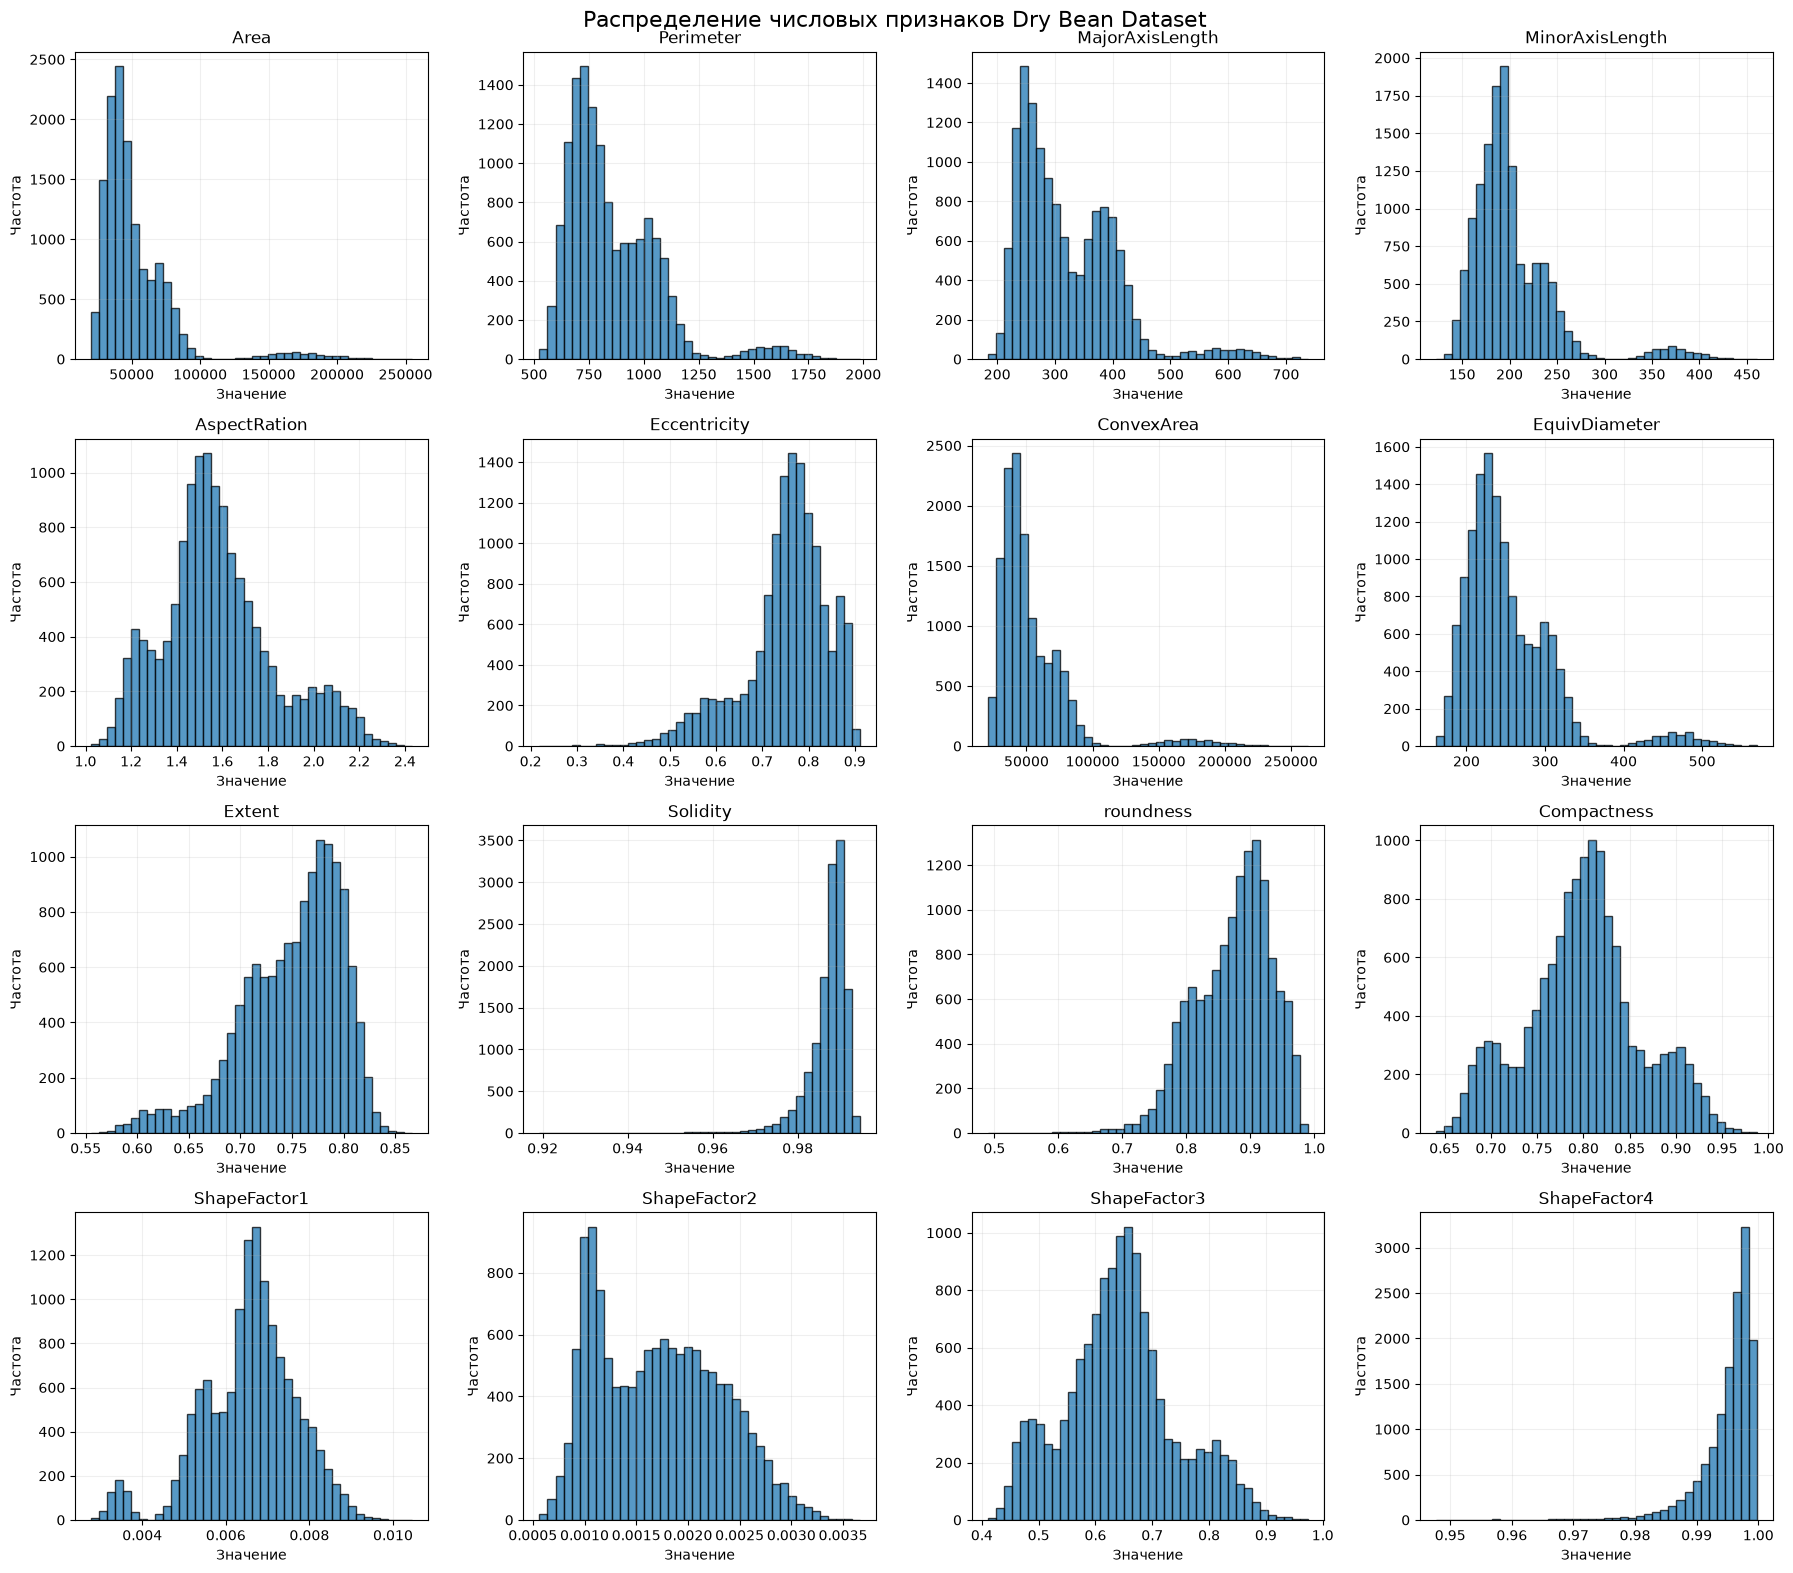

In [54]:
n_cols = 4
n_rows = int(np.ceil(X.shape[1] / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 16)
)

axes = axes.flatten()

for i, column in enumerate(X.columns):
    axes[i].hist(
        X[column],
        bins=40,
        edgecolor="black",
        alpha=0.75
    )

    axes[i].set_title(column)
    axes[i].set_xlabel("Значение")
    axes[i].set_ylabel("Частота")
    axes[i].grid(alpha=0.2)

for i in range(len(X.columns), len(axes)):
    axes[i].axis("off")

plt.suptitle(
    "Распределение числовых признаков Dry Bean Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

По гистограммам видно, что числовые признаки имеют различные распределения. Некоторые из них имеют выраженную асимметрию, например Area, ConvexArea и EquivDiameter. У ряда признаков наблюдается несколько пиков, что может указывать на наличие различных групп объектов в данных. Распределения признаков неоднородны и не все из них близки к нормальному распределению.

### Анализ выбросов


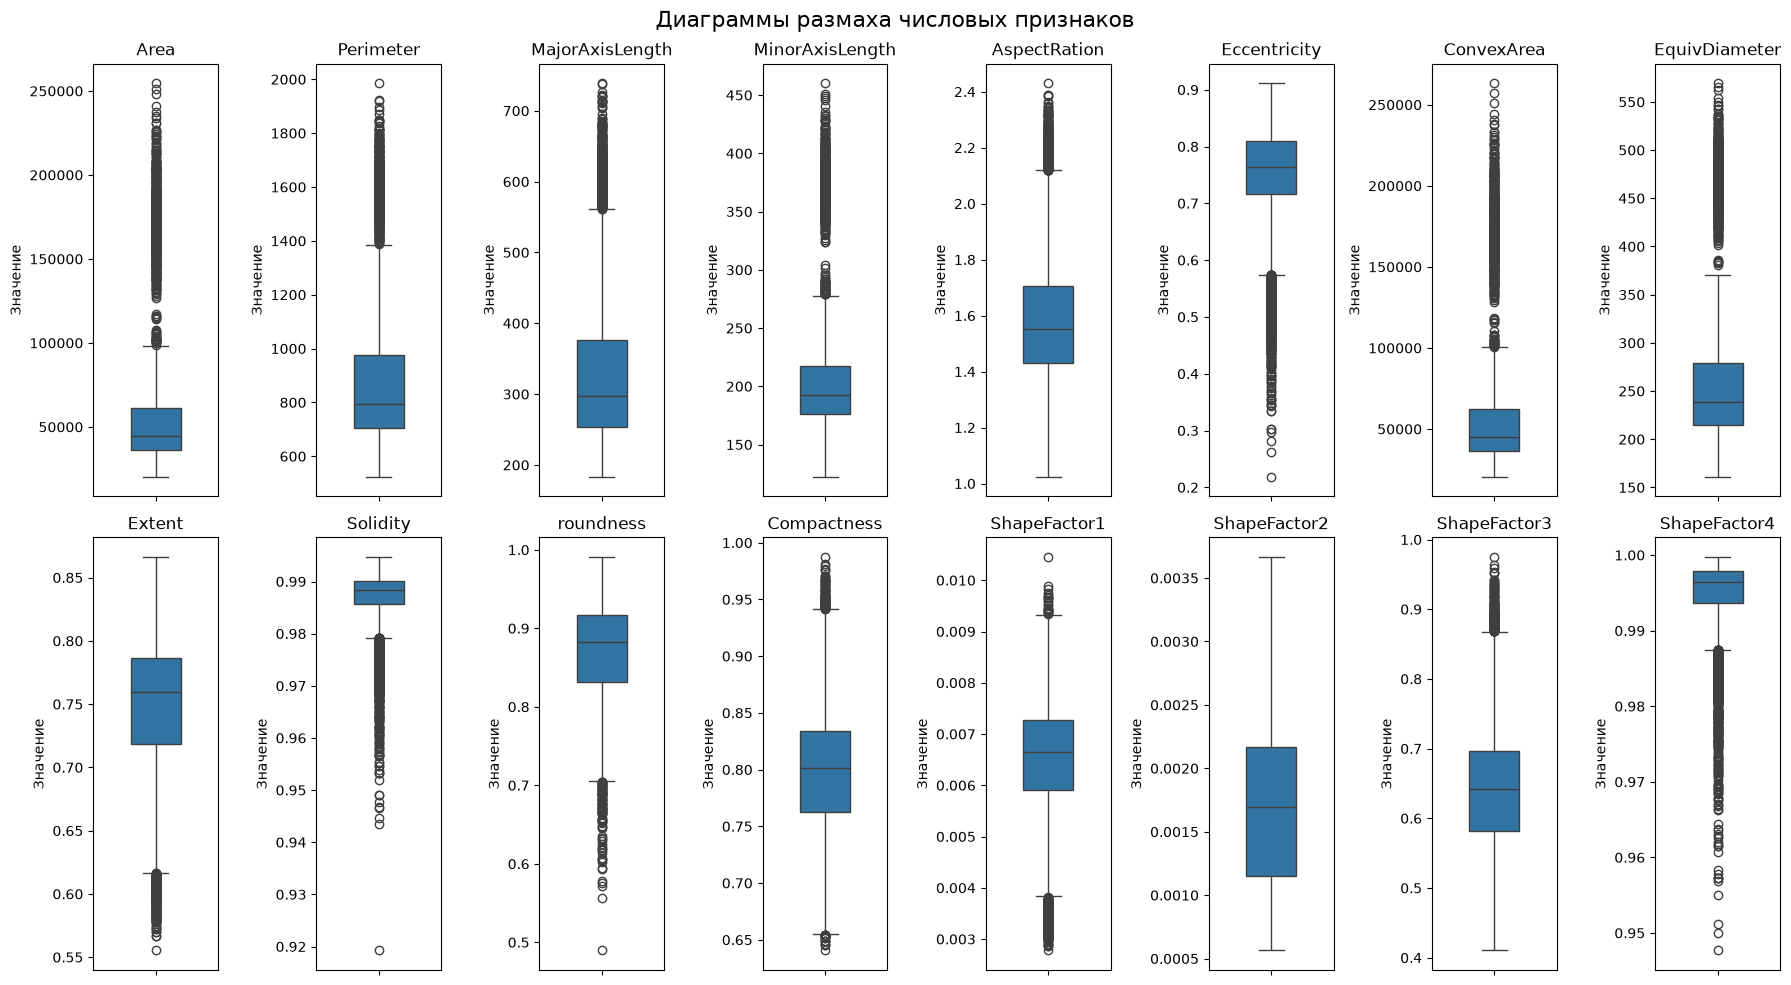

In [55]:
fig, axes = plt.subplots(
    2, 8,
    figsize=(18, 10)
)

axes = axes.flatten()

for i, column in enumerate(X.columns):
    sns.boxplot(
        y=X[column],
        ax=axes[i],
        width=0.4
    )

    axes[i].set_title(column)
    axes[i].set_ylabel("Значение")
    axes[i].set_xlabel("")

plt.suptitle(
    "Диаграммы размаха числовых признаков",
    fontsize=16
)

plt.tight_layout()
plt.show()

По диаграммам размаха видно, что во многих признаках присутствуют значения, расположенные за пределами основных диапазонов данных. Такие наблюдения могут рассматриваться как потенциальные выбросы.

Особенно заметны они у признаков Area, Perimeter, MajorAxisLength и ConvexArea. При этом наличие выбросов не обязательно означает ошибку в данных, поскольку они могут отражать реальные особенности объектов.

In [56]:
outlier_stats = []

for column in X.columns:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (X[column] < lower_bound) |
        (X[column] > upper_bound)
    )

    outlier_stats.append({
        "Признак": column,
        "Количество выбросов": outliers.sum(),
        "Доля выбросов, %": outliers.mean() * 100
    })

outlier_df = pd.DataFrame(outlier_stats)

print(
    outlier_df.sort_values(
        "Доля выбросов, %",
        ascending=False
    ).round(2)
)

            Признак  Количество выбросов  Доля выбросов, %
5      Eccentricity                  843              6.19
9          Solidity                  778              5.72
15     ShapeFactor4                  767              5.64
3   MinorAxisLength                  569              4.18
0              Area                  551              4.05
6        ConvexArea                  550              4.04
12     ShapeFactor1                  533              3.92
7     EquivDiameter                  526              3.86
1         Perimeter                  500              3.67
4      AspectRation                  473              3.48
2   MajorAxisLength                  379              2.78
8            Extent                  275              2.02
14     ShapeFactor3                  195              1.43
11      Compactness                  109              0.80
10        roundness                   91              0.67
13     ShapeFactor2                    0              0.

Для определения потенциальных выбросов использовался межквартильный размах (IQR). Наибольшая доля выбросов обнаружена у признаков Eccentricity (6,19%), Solidity (5,72%) и ShapeFactor4 (5,64%).

У признака ShapeFactor2 выбросы по выбранному критерию отсутствуют. В целом количество потенциальных выбросов различается в зависимости от признака.

Условие полного отсутствия выбросов в исходных данных не выполняется. Однако обнаруженные значения не удалялись, поскольку они могут отражать реальные особенности геометрии зёрен фасоли, а не ошибки измерений.

Поскольку выбросы могут влиять на результаты K-means и GMM, их наличие учитывается при последующей интерпретации результатов кластеризации.

### Анализ дисперсии числовых признаков

Для оценки разброса значений числовых признаков была рассчитана их дисперсия.

Дисперсия показывает, насколько сильно значения признака отклоняются от его среднего значения. Чем выше дисперсия, тем больше разброс данных, а низкая дисперсия указывает на более однородные значения признака.

Данный анализ позволяет определить признаки с наибольшей и наименьшей вариативностью, а также оценить различия в масштабах исходных данных перед выполнением стандартизации.

In [57]:
feature_variance = X.var().sort_values(ascending=False)

print(
    feature_variance.to_frame(
        name="Дисперсия признака"
    ).round(3)
)

                 Дисперсия признака
ConvexArea             8.865456e+08
Area                   8.599026e+08
Perimeter              4.592007e+04
MajorAxisLength        7.343494e+03
EquivDiameter          3.501932e+03
MinorAxisLength        2.022309e+03
AspectRation           6.100000e-02
ShapeFactor3           1.000000e-02
Eccentricity           8.000000e-03
Compactness            4.000000e-03
roundness              4.000000e-03
Extent                 2.000000e-03
Solidity               0.000000e+00
ShapeFactor4           0.000000e+00
ShapeFactor1           0.000000e+00
ShapeFactor2           0.000000e+00


Дисперсия признаков существенно различается. Наибольшие значения имеют ConvexArea и Area, тогда как у ShapeFactor1, ShapeFactor2, ShapeFactor4 и Solidity значения дисперсии значительно меньше.

Это объясняется тем, что признаки измеряются в разных масштабах и имеют разные диапазоны значений. Поэтому перед применением алгоритмов кластеризации необходимо выполнить стандартизацию данных, чтобы признаки с большими числовыми значениями не оказывали непропорционально сильного влияния на результат.

### Оценка информационной значимости признаков
На данном этапе проводится кластеризация объектов набора данных с использованием двух алгоритмов: K-means и Gaussian Mixture Model (GMM).

Кластеризация позволяет разделить объекты на группы на основе сходства их числовых признаков без использования заранее известных классов. 

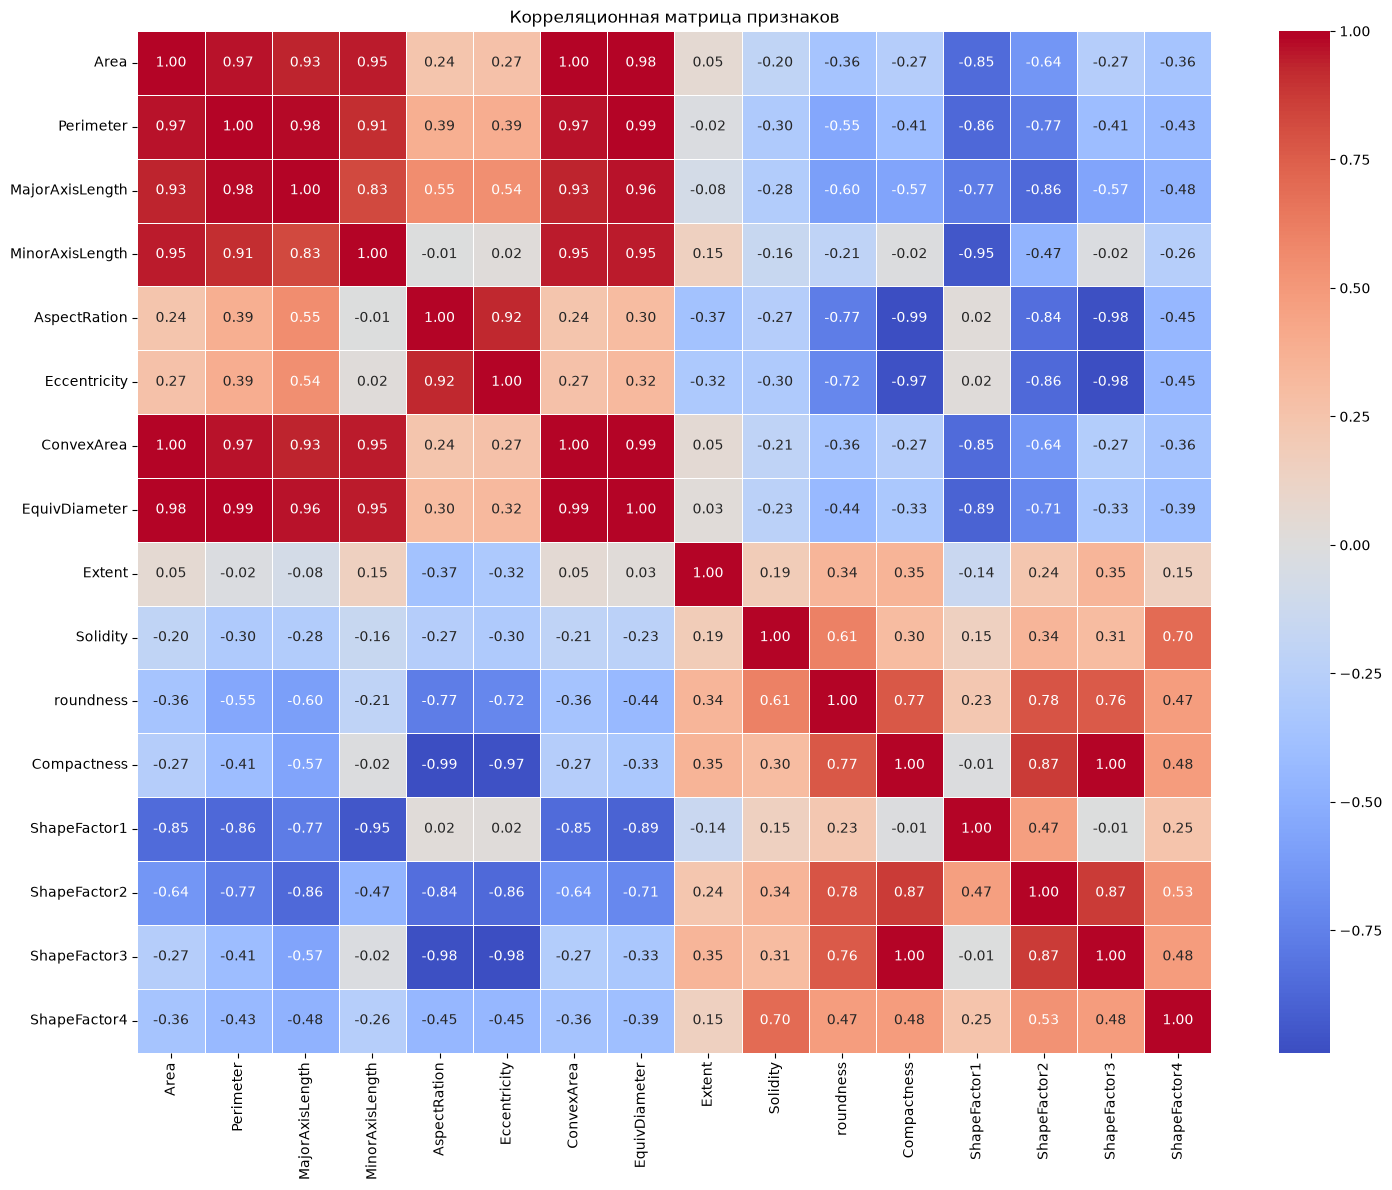

In [58]:
plt.figure(figsize=(15, 12))

correlation_matrix = X.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()

Корреляционная матрица показывает наличие сильных взаимосвязей между некоторыми признаками. Например, Area сильно коррелирует с Perimeter, MajorAxisLength, ConvexArea и EquivDiameter.

Также наблюдаются сильные взаимосвязи между AspectRation, Eccentricity, Compactness и ShapeFactor3.

Это говорит о том, что некоторые признаки содержат схожую информацию. Следовательно, в исходных данных присутствует определённая избыточность признакового пространства, которую необходимо учитывать при проведении кластеризации.

### Анализ главных компонент (PCA)

Перед выполнением кластеризации проводится анализ главных компонент (PCA). Сначала числовые признаки стандартизируются с помощью StandardScaler, после чего применяется метод главных компонент.

In [59]:
scaler_analysis = StandardScaler()

X_scaled_analysis = scaler_analysis.fit_transform(X)

pca_analysis = PCA()

X_pca_analysis = pca_analysis.fit_transform(
    X_scaled_analysis
)

pca_variance = pd.DataFrame({
    "Главная компонента": [
        f"PC{i+1}" for i in range(X.shape[1])
    ],
    "Объясненная дисперсия, %":
        pca_analysis.explained_variance_ratio_ * 100,
    "Накопленная дисперсия, %":
        np.cumsum(
            pca_analysis.explained_variance_ratio_
        ) * 100
})

print(pca_variance.round(2))

   Главная компонента  Объясненная дисперсия, %  Накопленная дисперсия, %
0                 PC1                     55.47                     55.47
1                 PC2                     26.43                     81.90
2                 PC3                      8.01                     89.90
3                 PC4                      5.11                     95.02
4                 PC5                      2.74                     97.76
5                 PC6                      1.15                     98.91
6                 PC7                      0.70                     99.60
7                 PC8                      0.33                     99.93
8                 PC9                      0.05                     99.98
9                PC10                      0.01                     99.99
10               PC11                      0.01                    100.00
11               PC12                      0.00                    100.00
12               PC13                 

Результаты PCA показывают, что первая главная компонента объясняет 55,47% общей дисперсии, а вторая - 26,43%. Вместе первые две компоненты сохраняют 81,90% информации исходных признаков.

Первые четыре компоненты объясняют уже 95,02% общей дисперсии. Это свидетельствует о том, что значительную часть информации исходного набора из 16 признаков можно представить с помощью меньшего количества компонент.

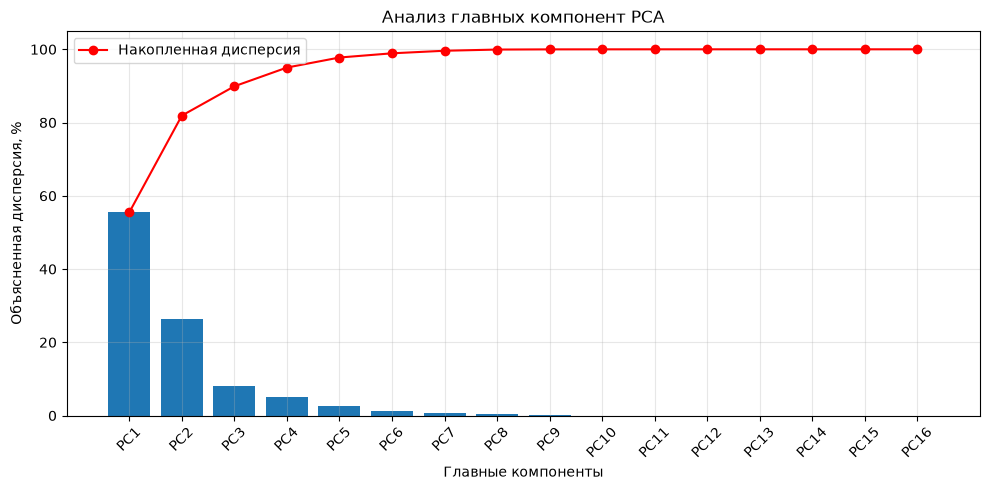

In [60]:
plt.figure(figsize=(10, 5))

plt.bar(
    pca_variance["Главная компонента"],
    pca_variance["Объясненная дисперсия, %"]
)

plt.plot(
    pca_variance["Главная компонента"],
    pca_variance["Накопленная дисперсия, %"],
    marker="o",
    color="red",
    label="Накопленная дисперсия"
)

plt.xlabel("Главные компоненты")
plt.ylabel("Объясненная дисперсия, %")
plt.title("Анализ главных компонент PCA")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Для наглядного представления результатов построен график объяснённой и накопленной дисперсии главных компонент.

По графику видно, что первые две главные компоненты объясняют примерно 82% общей дисперсии данных. При использовании первых четырёх компонент этот показатель составляет около 94%.

Таким образом, значительная часть информации исходных 16 признаков может быть представлена меньшим количеством главных компонент. Это подтверждает наличие взаимосвязей и избыточности в исходном наборе признаков.

### Удаление дубликатов

In [ ]:
print("Полных дубликатов:", df.duplicated().sum())

duplicate_features = (
    df.groupby(list(X.columns))["Class"]
    .nunique()
)

print(
    "Одинаковые наборы признаков с разными классами:",
    (duplicate_features > 1).sum()
)

df = df.drop_duplicates().copy()

X = df.drop(columns=["Class"])
y_true = df["Class"]

print("Размер данных после удаления дубликатов:", df.shape)
print("Оставшиеся дубликаты:", df.duplicated().sum())

Полных дубликатов: 68
Одинаковые наборы признаков с разными классами: 0
Размер данных после удаления дубликатов: (13543, 17)
Оставшиеся дубликаты: 0


В исходном наборе данных было обнаружено 68 полных дубликатов.
После очистки количество объектов сократилось с 13 611 до 13 543. Повторяющиеся строки отсутствуют.

## Стандартизация данных

Перед применением алгоритмов кластеризации необходимо привести признаки к единому масштабу. Исходные признаки имеют разные единицы измерения и диапазоны значений, поэтому признаки с большими числовыми значениями могут оказывать чрезмерное влияние на результаты кластеризации.

Для решения этой проблемы применяется метод стандартизации StandardScaler, который преобразует значения признаков таким образом, чтобы их среднее значение было равно 0, а стандартное отклонение - 1.

In [62]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

print("Данные после стандартизации:")
display(X_scaled.head())

print("\nСредние значения признаков:")
print(X_scaled.mean().round(4))

print("\nСтандартные отклонения признаков:")
print(X_scaled.std().round(4))

Данные после стандартизации:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,-0.838800,-1.139663,-1.301976,-0.632111,-1.565363,-2.182833,-0.839489,-1.060491,0.287981,0.366476,1.420346,1.838628,0.681918,2.398280,1.924811,0.838679
1,-0.827266,-1.010529,-1.391169,-0.435758,-1.972460,-3.685504,-0.824175,-1.041410,0.697598,-0.465886,0.224987,2.497622,0.369552,3.097471,2.691446,0.771141
2,-0.805287,-1.075303,-1.247807,-0.586775,-1.514305,-2.042229,-0.806818,-1.005357,0.577958,0.517614,1.248979,1.764053,0.604373,2.231086,1.840150,0.917418
3,-0.783920,-0.973894,-1.274241,-0.440595,-1.742960,-2.740196,-0.772170,-0.970686,0.671302,-2.248692,0.509588,2.082211,0.403254,2.511258,2.204306,-0.202373
4,-0.779429,-1.093821,-1.375750,-0.268281,-2.121534,-4.535823,-0.782457,-0.963445,0.475476,0.804605,1.872434,2.768598,0.120215,3.267675,3.016333,0.940406



Средние значения признаков:
Area               0.0
Perimeter          0.0
MajorAxisLength    0.0
MinorAxisLength   -0.0
AspectRation       0.0
Eccentricity      -0.0
ConvexArea         0.0
EquivDiameter     -0.0
Extent            -0.0
Solidity           0.0
roundness         -0.0
Compactness        0.0
ShapeFactor1       0.0
ShapeFactor2       0.0
ShapeFactor3       0.0
ShapeFactor4       0.0
dtype: float64

Стандартные отклонения признаков:
Area               1.0
Perimeter          1.0
MajorAxisLength    1.0
MinorAxisLength    1.0
AspectRation       1.0
Eccentricity       1.0
ConvexArea         1.0
EquivDiameter      1.0
Extent             1.0
Solidity           1.0
roundness          1.0
Compactness        1.0
ShapeFactor1       1.0
ShapeFactor2       1.0
ShapeFactor3       1.0
ShapeFactor4       1.0
dtype: float64


После применения StandardScaler были проверены средние значения и стандартные отклонения всех признаков.

Полученные результаты показывают, что средние значения признаков близки к 0, а стандартные отклонения равны 1. 

### Оценка информационной значимости признаков с помощью PCA

Для оценки вклада исходных признаков в общую изменчивость данных был выполнен анализ нагрузок главных компонент (PCA loadings).

Нагрузки показывают, насколько каждый исходный признак связан с главными компонентами. Чем больше абсолютное значение нагрузки, тем сильнее соответствующий признак влияет на данную компоненту.

Для анализа рассматриваются первые две главные компоненты, поскольку вместе они объясняют значительную часть общей дисперсии данных.

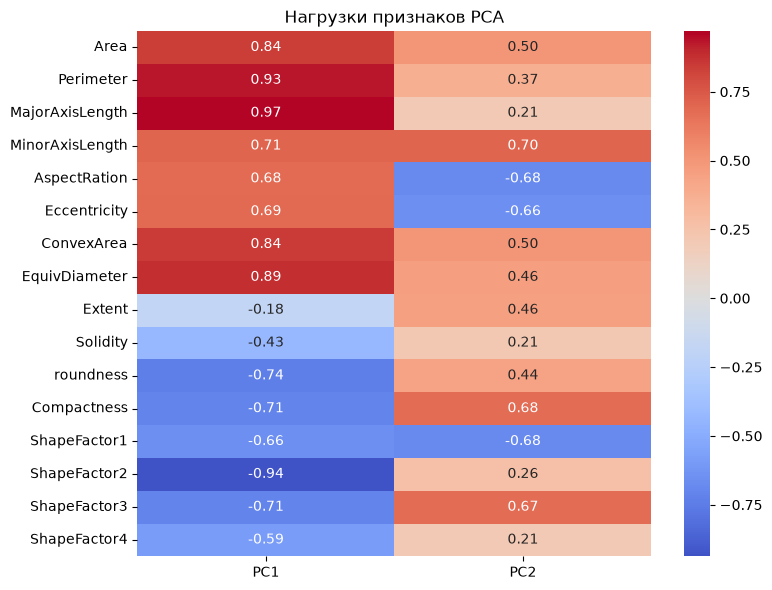

In [90]:
pca_loadings_model = PCA(n_components=2)
pca_loadings_model.fit(X_scaled)

loadings = pd.DataFrame(
    pca_loadings_model.components_.T *
    np.sqrt(pca_loadings_model.explained_variance_),
    index=X_scaled.columns,
    columns=["PC1", "PC2"]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    loadings,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Нагрузки признаков PCA")
plt.tight_layout()
plt.show()

**Первая главная компонента (PC1)** в наибольшей степени связана с признаками MajorAxisLength (0,971), Perimeter (0,926), EquivDiameter (0,887), ConvexArea (0,844) и Area (0,842). Это позволяет интерпретировать PC1 преимущественно как компоненту, отражающую геометрические размеры фасолин. Отрицательные нагрузки ShapeFactor2 (-0,938) и roundness (-0,739) также указывают на связь этой компоненты с характеристиками формы.

**Вторая главная компонента (PC2)** имеет наиболее выраженные положительные нагрузки у MinorAxisLength (0,704), Compactness (0,676) и ShapeFactor3 (0,673), а также отрицательные нагрузки у ShapeFactor1 (-0,682), AspectRation (-0,680) и Eccentricity (-0,657). Следовательно, PC2 в большей степени отражает особенности формы и пропорций объектов.

Первые две главные компоненты описывают разные характеристики фасолин: PC1 преимущественно связана с размерами, а PC2 - с особенностями их формы.

## Визуальный анализ структуры данных

Для предварительной оценки структуры данных была построена матрица диаграмм рассеивания (Scatter Matrix).

Для построения графика выбраны несколько геометрических признаков, характеризующих размеры и форму фасоли. Чтобы график оставался наглядным и не перегружался большим количеством точек, используется случайная выборка объектов.

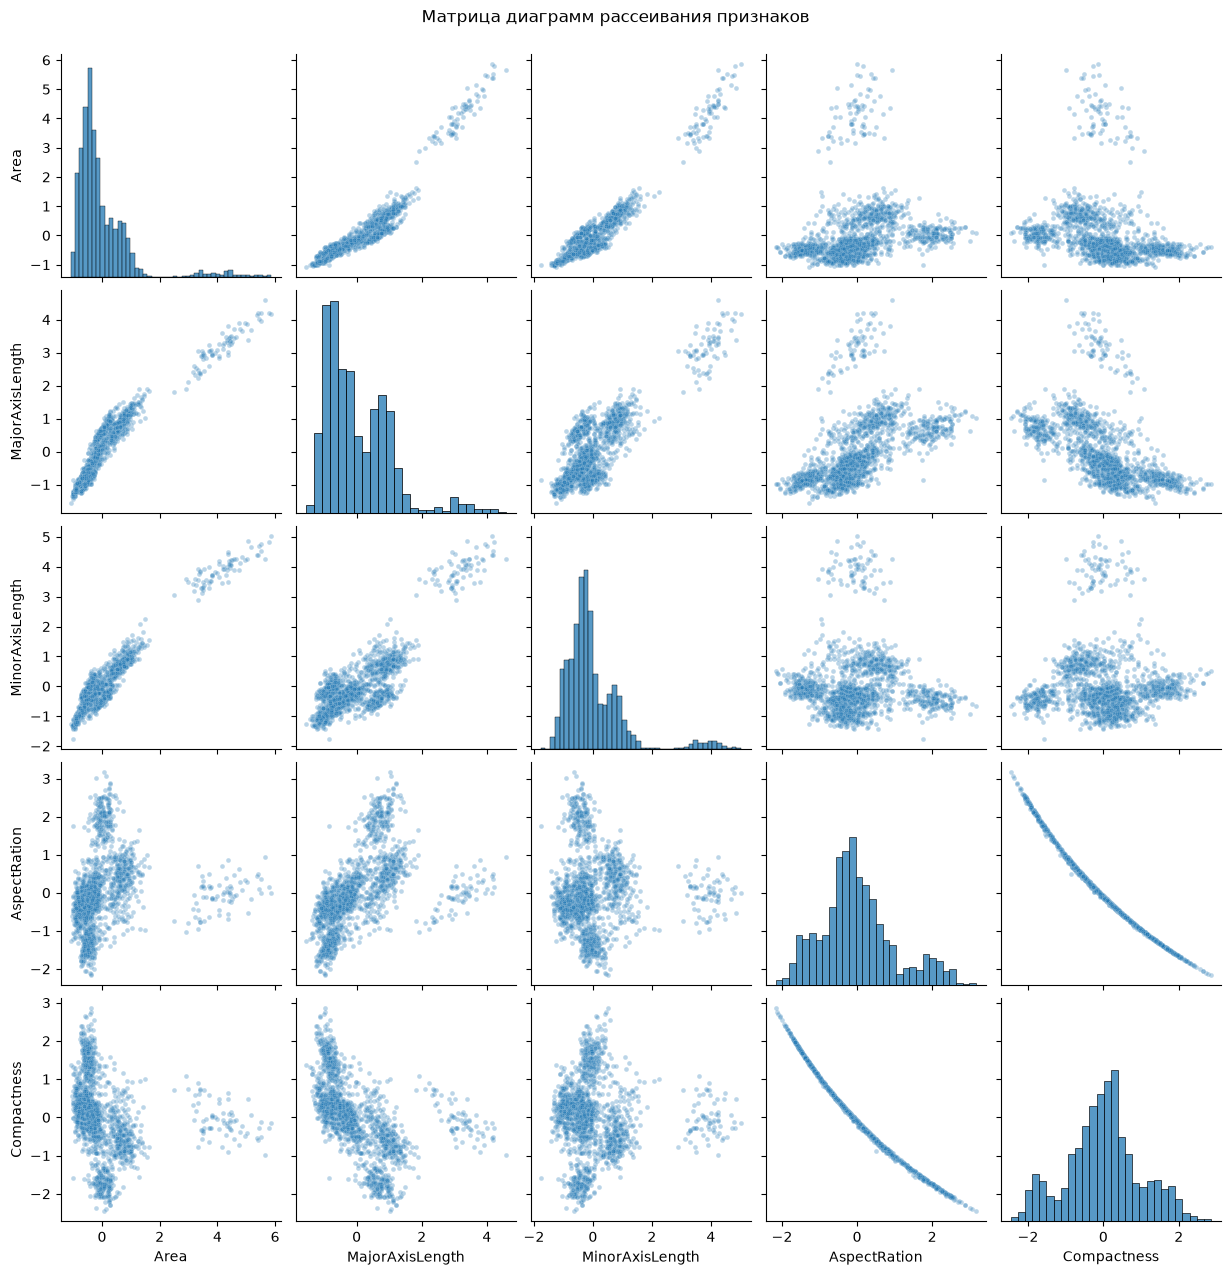

In [ ]:
selected_features = [
    "Area",
    "MajorAxisLength",
    "MinorAxisLength",
    "AspectRation",
    "Compactness"
]

plot_data = X_scaled[selected_features].sample(
    n=1500,
    random_state=42
)

sns.pairplot(
    plot_data,
    diag_kind="hist",
    plot_kws={"alpha": 0.3, "s": 12}
)

plt.suptitle(
    "Матрица диаграмм рассеивания признаков",
    y=1.02
)

plt.show()

По матрице диаграмм рассеивания наблюдается выраженная взаимосвязь между некоторыми признаками. В частности, Area, MajorAxisLength и MinorAxisLength имеют положительную корреляцию. Между AspectRation и Compactness прослеживается нелинейная обратная зависимость.

В пространстве признаков можно заметить отдельные скопления объектов, однако некоторые из них пересекаются. Также наблюдаются группы различной плотности и вытянутой формы.

Структура данных является неоднородной и не позволяет однозначно определить количество кластеров только по визуальному анализу. Для дальнейшего выбора количества кластеров будут использованы метод локтя и силуэтный анализ.

## Выбор методов кластеризации

С учётом особенностей структуры данных для исследования выбраны два алгоритма: K-means и Gaussian Mixture Model (GMM).

Метод K-means выбран в качестве базового алгоритма, поскольку он позволяет выделять группы объектов на основе расстояния до центров кластеров. С его помощью можно оценить, насколько хорошо данные разделяются на компактные группы.

Gaussian Mixture Model выбран как альтернативный вероятностный метод. В отличие от K-means, он позволяет моделировать кластеры эллиптической формы и учитывать различия в их дисперсии и ориентации.

Использование двух алгоритмов позволит сравнить результаты разных подходов к кластеризации и определить, какой из них лучше описывает структуру исследуемых данных.

### Определение оптимального количества кластеров для K-means

Для выбора подходящего количества кластеров алгоритм K-means обучается с различными значениями параметра k - от 2 до 12.

Для каждого значения рассчитываются две метрики:

- **Inertia** - сумма квадратов расстояний объектов до центров соответствующих кластеров. Чем меньше значение, тем компактнее кластеры.
- **Silhouette Score** - коэффициент силуэта, оценивающий одновременно внутрикластерную компактность и разделённость кластеров. Чем ближе значение к 1, тем лучше разделены группы.

Полученные результаты позволяют сравнить качество кластеризации при разном количестве кластеров и определить наиболее подходящее значение k.

In [94]:
inertia = []
silhouette_scores = []

k_range = range(2, 13)

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

    
results = pd.DataFrame({
    "Количество кластеров (k)": list(k_range),
    "Inertia": inertia,
    "Silhouette Score": silhouette_scores
})

print(results.round(4))

    Количество кластеров (k)      Inertia  Silhouette Score
0                          2  129194.0199            0.3972
1                          3   94331.7347            0.4044
2                          4   75993.1949            0.3423
3                          5   61624.6374            0.3572
4                          6   54900.7483            0.3599
5                          7   48671.4570            0.3088
6                          8   45083.3590            0.3027
7                          9   41904.8161            0.3029
8                         10   39707.1258            0.2681
9                         11   37774.5769            0.2887
10                        12   35986.4486            0.2619


При увеличении количества кластеров значение Inertia постепенно уменьшается, поскольку объекты распределяются по большему числу групп.

Наибольшее значение Silhouette Score (0,4044) получено при k = 3. Это указывает на наиболее удачное соотношение внутрикластерной компактности и межкластерной разделённости среди рассмотренных вариантов.

Таким образом, для дальнейшей кластеризации методом K-means выбирается k = 3.

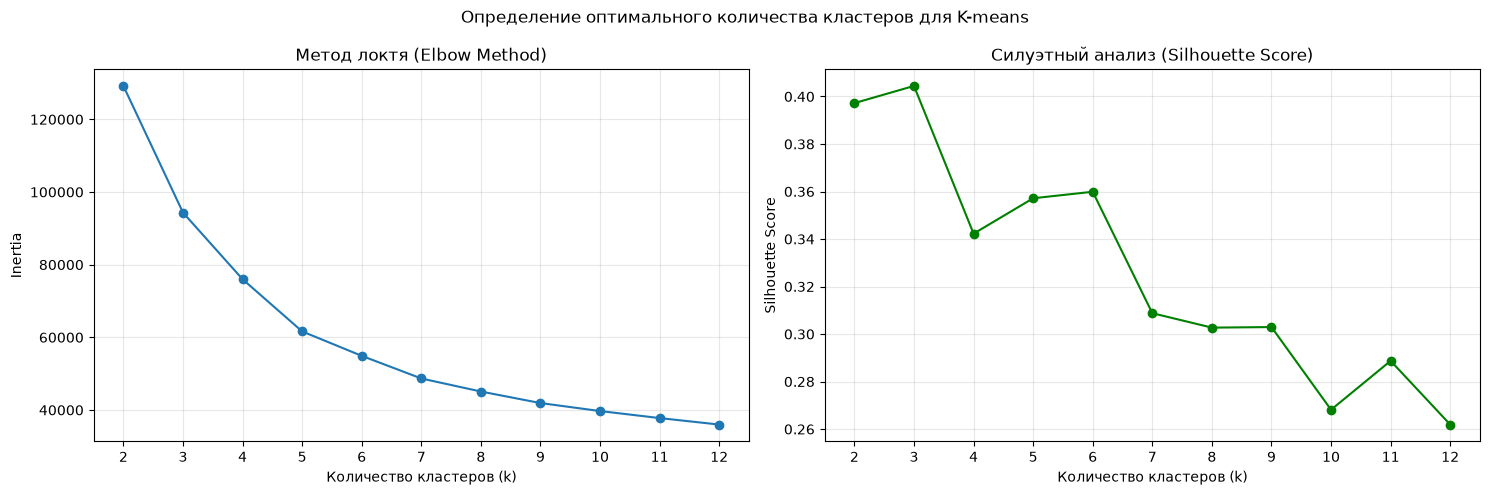

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(k_range, inertia, marker="o")
axes[0].set_title("Метод локтя (Elbow Method)")
axes[0].set_xlabel("Количество кластеров (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_range))
axes[0].grid(alpha=0.3)

axes[1].plot(k_range, silhouette_scores, marker="o", color="green")
axes[1].set_title("Силуэтный анализ (Silhouette Score)")
axes[1].set_xlabel("Количество кластеров (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_range))
axes[1].grid(alpha=0.3)

plt.suptitle("Определение оптимального количества кластеров для K-means")
plt.tight_layout()
plt.show()

По графику метода локтя видно, что при увеличении количества кластеров значение Inertia постепенно уменьшается. Наиболее заметное снижение наблюдается в диапазоне от 2 до 5 кластеров, после чего уменьшение становится менее выраженным.

Результаты силуэтного анализа показывают, что наибольшее значение Silhouette Score достигается при k = 3 и составляет 0,4044. Это указывает на то, что среди проверенных вариантов три кластера обеспечивают наиболее удачное разделение объектов.

Таким образом, по результатам силуэтного анализа предварительно выбрано оптимальное количество кластеров k = 3. При этом метод локтя также указывает на возможную целесообразность рассмотрения 4–5 кластеров.

### Кластеризация методом K-means

На основании результатов метода локтя и силуэтного анализа для алгоритма K-means выбрано количество кластеров k = 3.

Для реализации используется алгоритм K-means с параметром `n_init = 10`, который задаёт количество запусков алгоритма с различными начальными положениями центров кластеров. Для воспроизводимости результатов установлен `random_state = 42`.

In [95]:
kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

print("Кластеризация K-means завершена!")
print("\nКоличество объектов в каждом кластере:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

print("\nИтоговое значение Inertia:")
print(round(kmeans_model.inertia_, 4))

Кластеризация K-means завершена!

Количество объектов в каждом кластере:
KMeans_Cluster
0    7567
1     524
2    5452
Name: count, dtype: int64

Итоговое значение Inertia:
94331.7347


В результате применения алгоритма K-means с количеством кластеров k = 3 все 13 543 объекта были распределены по трём группам:

- Кластер 0 - 7567 объектов.
- Кластер 1 - 524 объекта.
- Кластер 2 - 5452 объекта.

Распределение показывает, что кластеры имеют разную численность. Особенно выделяется кластер 1, содержащий значительно меньше объектов по сравнению с остальными группами.

Значение Inertia составило 94331,7347, что характеризует суммарное внутрикластерное расстояние объектов до центров своих кластеров.

По результатам оценки качества Silhouette Score составил 0,4044, что указывает на умеренное разделение кластеров. Значение Calinski-Harabasz Index равно 8781,2651, а Davies-Bouldin Index - 0,9013.

### Оценка качества кластеризации K-means

Для оценки качества полученного разбиения используются внутренние и внешние метрики.

Внутренние метрики позволяют оценить компактность кластеров и степень их разделения между собой. Внешние метрики используются для сравнения результатов кластеризации с исходными классами фасоли, которые не передавались алгоритму при обучении.

In [ ]:
kmeans_metrics = {
    "Silhouette Score": silhouette_score(X_scaled, kmeans_labels),
    "Calinski-Harabasz Index": calinski_harabasz_score(X_scaled, kmeans_labels),
    "Davies-Bouldin Index": davies_bouldin_score(X_scaled, kmeans_labels),
    "Adjusted Rand Index": adjusted_rand_score(y_true, kmeans_labels),
    "Normalized Mutual Information": normalized_mutual_info_score(y_true, kmeans_labels)
}

kmeans_metrics_df = pd.DataFrame(
    list(kmeans_metrics.items()),
    columns=["Метрика", "Значение"]
)

print(kmeans_metrics_df.round(4))

                         Метрика   Значение
0               Silhouette Score     0.4044
1        Calinski-Harabasz Index  8781.2651
2           Davies-Bouldin Index     0.9013
3            Adjusted Rand Index     0.2976
4  Normalized Mutual Information     0.4856


Внешние метрики показали следующие результаты: Adjusted Rand Index (ARI) - 0,2976, Normalized Mutual Information (NMI) - 0,4856. Это свидетельствует о наличии определённого соответствия между полученными кластерами и исходными классами фасоли, однако полного совпадения нет.

### Подбор количества компонент для Gaussian Mixture Model

Для определения оптимального количества компонент модели Gaussian Mixture Model используются информационные критерии AIC и BIC, а также силуэтный коэффициент.

Критерии AIC и BIC позволяют оценить качество вероятностной модели с учётом её сложности. Предпочтительными считаются модели с меньшими значениями данных критериев. Силуэтный коэффициент дополнительно позволяет оценить компактность и разделённость полученных кластеров.

In [96]:
aic_scores = []
bic_scores = []
gmm_silhouette_scores = []

k_range_gmm = range(2, 13)

for k in k_range_gmm:
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=3,
        reg_covar=1e-5
    )

    gmm.fit(X_scaled)

    labels = gmm.predict(X_scaled)

    aic_scores.append(gmm.aic(X_scaled))
    bic_scores.append(gmm.bic(X_scaled))

    gmm_silhouette_scores.append(
        silhouette_score(
            X_scaled,
            labels,
            sample_size=3000,
            random_state=42
        )
    )


gmm_results = pd.DataFrame({
    "Количество компонент (k)": list(k_range_gmm),
    "AIC": aic_scores,
    "BIC": bic_scores,
    "Silhouette Score": gmm_silhouette_scores
})

print(gmm_results.round(4))

    Количество компонент (k)          AIC          BIC  Silhouette Score
0                          2 -625445.1992 -623153.5435            0.3902
1                          3 -691925.2930 -688484.0528            0.4014
2                          4 -768496.6482 -763905.8233            0.3123
3                          5 -799477.2835 -793736.8740            0.3525
4                          6 -831409.1154 -824519.1212            0.2982
5                          7 -858542.3562 -850502.7774            0.2958
6                          8 -871866.5319 -862677.3685            0.2420
7                          9 -885834.8920 -875496.1439            0.2545
8                         10 -894538.3514 -883050.0186            0.2160
9                         11 -907391.3286 -894753.4112            0.1949
10                        12 -914252.7772 -900465.2752            0.1927


Анализ таблицы подтверждает результаты графиков. Наибольшее значение Silhouette Score (0,4014) получено при количестве компонент k = 3.

Минимальные значения AIC (-914252,7772) и BIC (-900465,2752) получены при k = 12. С учётом результатов силуэтного анализа для дальнейшей реализации GMM предварительно выбирается модель с тремя компонентами.

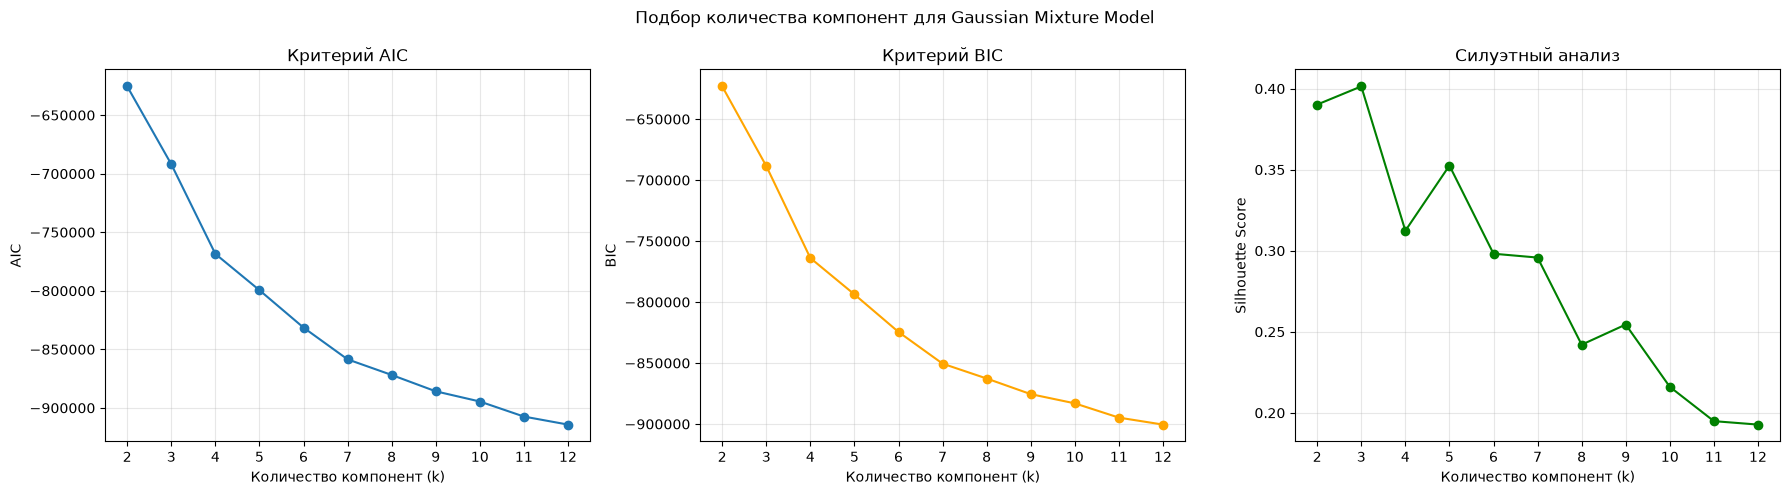

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(k_range_gmm, aic_scores, marker="o")
axes[0].set_title("Критерий AIC")
axes[0].set_xlabel("Количество компонент (k)")
axes[0].set_ylabel("AIC")
axes[0].set_xticks(list(k_range_gmm))
axes[0].grid(alpha=0.3)

axes[1].plot(k_range_gmm, bic_scores, marker="o", color="orange")
axes[1].set_title("Критерий BIC")
axes[1].set_xlabel("Количество компонент (k)")
axes[1].set_ylabel("BIC")
axes[1].set_xticks(list(k_range_gmm))
axes[1].grid(alpha=0.3)

axes[2].plot(
    k_range_gmm,
    gmm_silhouette_scores,
    marker="o",
    color="green"
)
axes[2].set_title("Силуэтный анализ")
axes[2].set_xlabel("Количество компонент (k)")
axes[2].set_ylabel("Silhouette Score")
axes[2].set_xticks(list(k_range_gmm))
axes[2].grid(alpha=0.3)

plt.suptitle("Подбор количества компонент для Gaussian Mixture Model")
plt.tight_layout()
plt.show()

По графикам AIC и BIC видно, что при увеличении количества компонент значения обоих критериев постепенно уменьшаются. Минимальные значения достигаются при k = 12, поэтому в исследуемом диапазоне данные критерии не позволяют однозначно определить оптимальное количество компонент.

Силуэтный анализ показывает, что наибольшее значение коэффициента достигается при k = 3 и составляет 0,4014. При дальнейшем увеличении количества компонент значение преимущественно снижается.

Таким образом, по результатам силуэтного анализа предварительно выбирается 3 компоненты для модели GMM.

### Кластеризация методом Gaussian Mixture Model
Для построения модели используется полная ковариационная матрица (`covariance_type="full"`), позволяющая учитывать различную форму и ориентацию кластеров. Параметр `random_state=42` обеспечивает воспроизводимость результатов, а `n_init=3` задаёт количество запусков модели с разными начальными параметрами.

In [97]:
gmm_model = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42,
    n_init=3,
    reg_covar=1e-5
)

gmm_model.fit(X_scaled)

gmm_labels = gmm_model.predict(X_scaled)

df_gmm = df.copy()
df_gmm["GMM_Cluster"] = gmm_labels

print("Количество объектов в каждом кластере:")

print(
    df_gmm["GMM_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame(name="Количество объектов")
)

Количество объектов в каждом кластере:
             Количество объектов
GMM_Cluster                     
0                           7715
1                            524
2                           5304


В результате применения алгоритма Gaussian Mixture Model с тремя компонентами все 13 543 объекта были распределены по следующим группам:

- Кластер 0 - 7715 объектов.
- Кластер 1 - 524 объекта.
- Кластер 2 - 5304 объекта.

Полученное распределение показывает, что кластеры имеют различную численность. Наиболее многочисленным является кластер 0, а наименее многочисленным - кластер 1.

Интересно, что распределение объектов по кластерам GMM близко к результатам K-means: оба алгоритма выделили небольшую группу из 524 объектов. Это может указывать на наличие устойчивой обособленной группы в данных.

### Оценка качества кластеризации GMM

Для оценки результатов Gaussian Mixture Model используются внутренние и внешние метрики качества.

Внутренние метрики позволяют оценить компактность и разделённость полученных кластеров. Внешние метрики сравнивают результаты кластеризации с исходными классами фасоли, которые не использовались при обучении модели.

In [98]:
gmm_metrics = {
    "Silhouette Score": silhouette_score(X_scaled, gmm_labels),
    "Calinski-Harabasz Index": calinski_harabasz_score(X_scaled, gmm_labels),
    "Davies-Bouldin Index": davies_bouldin_score(X_scaled, gmm_labels),
    "Adjusted Rand Index": adjusted_rand_score(y_true, gmm_labels),
    "Normalized Mutual Information": normalized_mutual_info_score(y_true, gmm_labels)
}

gmm_metrics_df = pd.DataFrame(
    list(gmm_metrics.items()),
    columns=["Метрика", "Значение"]
)

print(gmm_metrics_df.round(4))

                         Метрика   Значение
0               Silhouette Score     0.4057
1        Calinski-Harabasz Index  8628.5290
2           Davies-Bouldin Index     0.9104
3            Adjusted Rand Index     0.3133
4  Normalized Mutual Information     0.5120


По результатам оценки качества Gaussian Mixture Model получены следующие значения метрик:

- Silhouette Score - 0,4057.
- Calinski-Harabasz Index - 8628,5290.
- Davies-Bouldin Index - 0,9104.
- Adjusted Rand Index - 0,3133.
- Normalized Mutual Information - 0,5120.

Значение Silhouette Score указывает на умеренное разделение полученных кластеров. Значение Calinski-Harabasz Index характеризует соотношение межкластерного и внутрикластерного разброса, а Davies-Bouldin Index позволяет оценить сходство кластеров между собой.

Внешние метрики ARI и NMI показывают наличие соответствия между результатами кластеризации и исходными классами фасоли. Однако полученное разбиение не полностью совпадает с исходным распределением сортов.

## Сравнение качества кластеризации

Для сравнения результатов двух алгоритмов была составлена общая таблица внутренних и внешних метрик качества.

Это позволяет оценить компактность кластеров, степень их разделения и соответствие полученных групп исходным классам фасоли.

In [99]:
comparison_df = pd.DataFrame({
    "Метрика": list(kmeans_metrics.keys()),
    "K-means": list(kmeans_metrics.values()),
    "GMM": list(gmm_metrics.values())
})

print(comparison_df.round(4))

                         Метрика    K-means        GMM
0               Silhouette Score     0.4044     0.4057
1        Calinski-Harabasz Index  8781.2651  8628.5290
2           Davies-Bouldin Index     0.9013     0.9104
3            Adjusted Rand Index     0.2976     0.3133
4  Normalized Mutual Information     0.4856     0.5120


Сравнение показало, что GMM имеет немного более высокий Silhouette Score (0,4057 против 0,4044 у K-means), а также лучшие значения внешних метрик ARI (0,3133 против 0,2976) и NMI (0,5120 против 0,4856).

В то же время K-means показал более высокое значение Calinski-Harabasz Index (8781,2651 против 8628,5290) и более низкое значение Davies-Bouldin Index (0,9013 против 0,9104).

Таким образом, однозначного преимущества одного алгоритма по всем метрикам нет. Однако GMM немного лучше согласуется с исходными классами фасоли, тогда как K-means показывает несколько лучшие внутренние показатели компактности и разделения кластеров.

## Исследование влияния количества кластеров.

In [101]:
kmeans_parameter_results = []

for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    kmeans_parameter_results.append({
        "Количество кластеров": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels)
    })

kmeans_parameter_df = pd.DataFrame(kmeans_parameter_results)
display(kmeans_parameter_df.round(4))

,Количество кластеров,Inertia,Silhouette Score,Calinski-Harabasz,Davies-Bouldin
0,2,129194.0199,0.3972,9170.3624,1.0793
1,3,94331.7347,0.4044,8781.2651,0.9013
2,4,75993.1949,0.3423,8355.4286,0.9276
3,5,61624.6374,0.3572,8516.2717,1.0256
4,6,54900.7483,0.3599,7978.4532,0.9961
5,7,48671.4570,0.3088,7787.8367,1.1021


При увеличении количества кластеров значение Inertia постепенно уменьшается. Это ожидаемо, поскольку с ростом числа кластеров объекты распределяются по более многочисленным группам.

Наилучшее значение Silhouette Score (0,4044) достигается при k = 3. При этом Davies-Bouldin Index также имеет минимальное значение (0,9013), что указывает на более удачное соотношение компактности кластеров и расстояния между ними.

Значение Calinski-Harabasz Index максимально при k = 2 (9170,3624), однако при k = 3 оно также остаётся высоким (8781,2651).

Несмотря на отдельные преимущества других значений k по некоторым метрикам, выбор трёх кластеров является наиболее обоснованным по совокупности рассмотренных показателей.

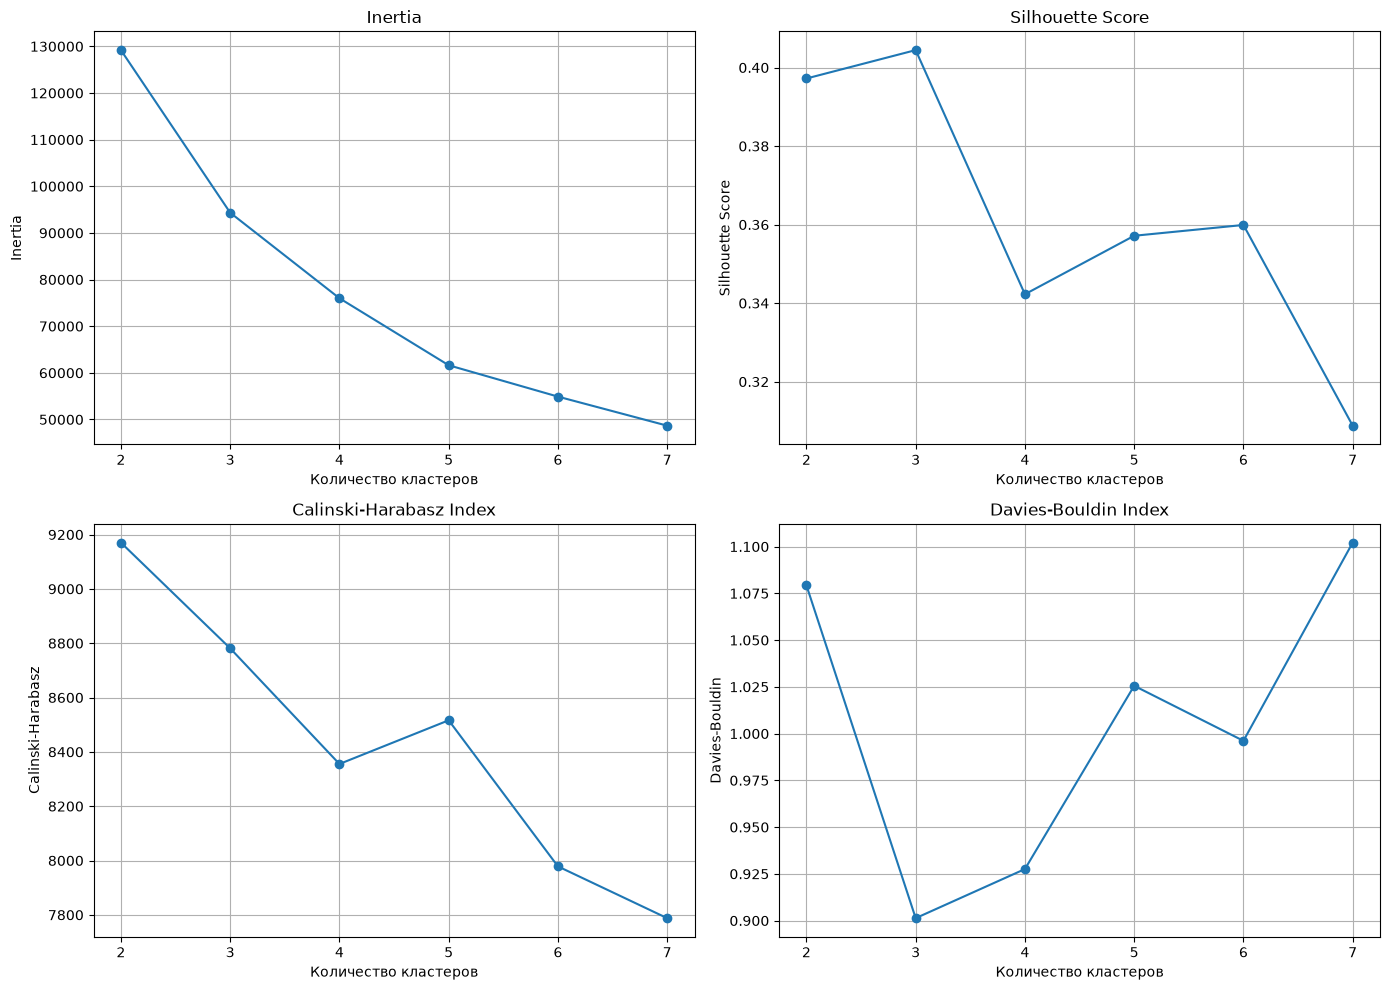

In [102]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics = [
    ("Inertia", "Inertia"),
    ("Silhouette Score", "Silhouette Score"),
    ("Calinski-Harabasz", "Calinski-Harabasz Index"),
    ("Davies-Bouldin", "Davies-Bouldin Index")
]

for ax, (column, title) in zip(axes.flat, metrics):
    ax.plot(
        kmeans_parameter_df["Количество кластеров"],
        kmeans_parameter_df[column],
        marker="o"
    )
    ax.set_title(title)
    ax.set_xlabel("Количество кластеров")
    ax.set_ylabel(column)
    ax.set_xticks(kmeans_parameter_df["Количество кластеров"])
    ax.grid(True)

plt.tight_layout()
plt.show()

По графику Inertia видно, что при увеличении количества кластеров значение функции постепенно уменьшается. Наиболее заметное снижение наблюдается при переходе от 2 к 3 кластерам, после чего темп уменьшения становится менее выраженным.

Silhouette Score достигает максимума при k = 3 (0,4044), что свидетельствует о наиболее удачном разделении объектов на группы среди рассмотренных вариантов.

Calinski-Harabasz Index имеет максимальное значение при k = 2, однако при k = 3 показатель также остаётся достаточно высоким.

Минимальное значение Davies-Bouldin Index (0,9013) наблюдается при k = 3, что говорит о хорошей компактности кластеров и их разделении.

## PCA и визуализация результатов кластеризации

In [103]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

print("Объяснённая дисперсия:")
print(pca_2d.explained_variance_ratio_)
print("Суммарная доля:", pca_2d.explained_variance_ratio_.sum())

Объяснённая дисперсия:
[0.55546808 0.26360789]
Суммарная доля: 0.8190759716525311


Первая главная компонента объясняет 55,55% общей дисперсии данных, вторая - 26,36%.

В совокупности две компоненты сохраняют 81,91% информации исходного пространства признаков.

Таким образом, снижение размерности с 16 до 2 признаков позволяет сохранить значительную часть информации и использовать полученное представление для визуального анализа результатов кластеризации.

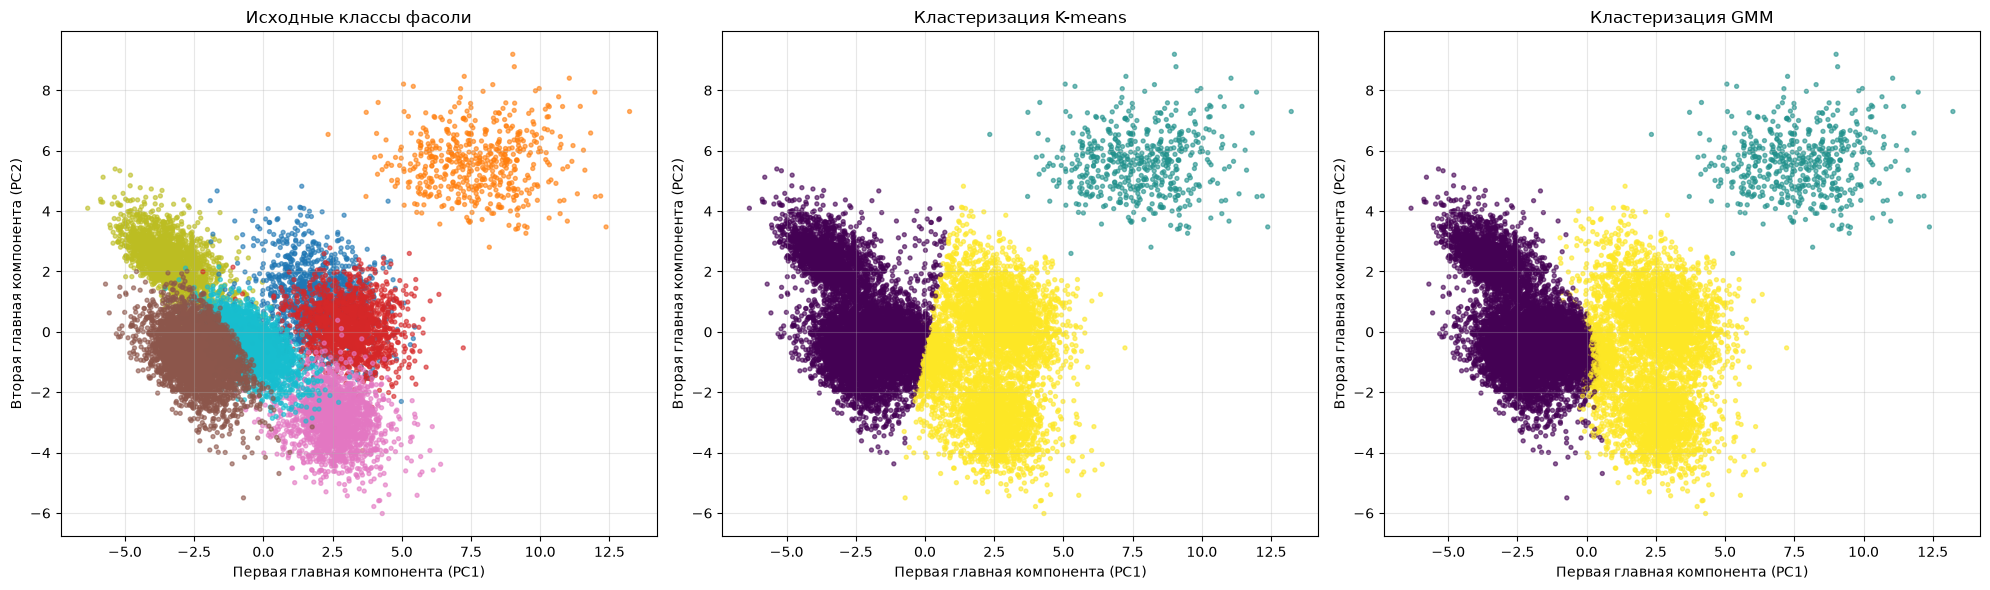

In [104]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Исходные классы
true_labels, y_encoded = np.unique(y_true, return_inverse=True)

scatter = axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=y_encoded, cmap="tab10", s=8, alpha=0.6
)
axes[0].set_title("Исходные классы фасоли")

# K-means
axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=kmeans_labels, cmap="viridis", s=8, alpha=0.6
)
axes[1].set_title("Кластеризация K-means")

# GMM
axes[2].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=gmm_labels, cmap="viridis", s=8, alpha=0.6
)
axes[2].set_title("Кластеризация GMM")

for ax in axes:
    ax.set_xlabel("Первая главная компонента (PC1)")
    ax.set_ylabel("Вторая главная компонента (PC2)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Для визуального сравнения результатов кластеризации построены три диаграммы рассеяния в пространстве первых двух главных компонент PCA. На первой диаграмме представлены исходные классы фасоли, на второй — результаты кластеризации методом K-means, на третьей — результаты GMM.

В исходных данных некоторые классы хорошо отделяются друг от друга, например BOMBAY, тогда как другие имеют области пересечения.

##### Интерпретация кластеризации K-means в пространстве PCA
На двумерной проекции PCA наблюдаются три сформированных кластера.

Зеленый кластер хорошо отделён от остальных и расположен в верхней правой части графика. Кластеры желтый и фиолетовый находятся ближе друг к другу, их области частично пересекаются. K-means достаточно чётко выделяет одну группу объектов, однако между двумя другими группами сохраняется некоторое сходство.

##### Интерпретация кластеризации GMM в пространстве PCA

На двумерной проекции PCA также наблюдаются три группы объектов.

Визуальное распределение кластеров GMM очень похоже на результат K-means. Это согласуется с ранее полученными значениями метрик и близкими характеристиками центров кластеров.


Оба алгоритма сформировали по три кластера. При этом визуальное распределение групп K-means и GMM практически совпадает.

Следует отметить, что алгоритмы объединяют несколько исходных классов в одну группу, поскольку количество кластеров было заранее ограничено тремя. Поэтому полученные кластеры не соответствуют исходным классам один к одному.

## Сравнение кластеров с исходными классами

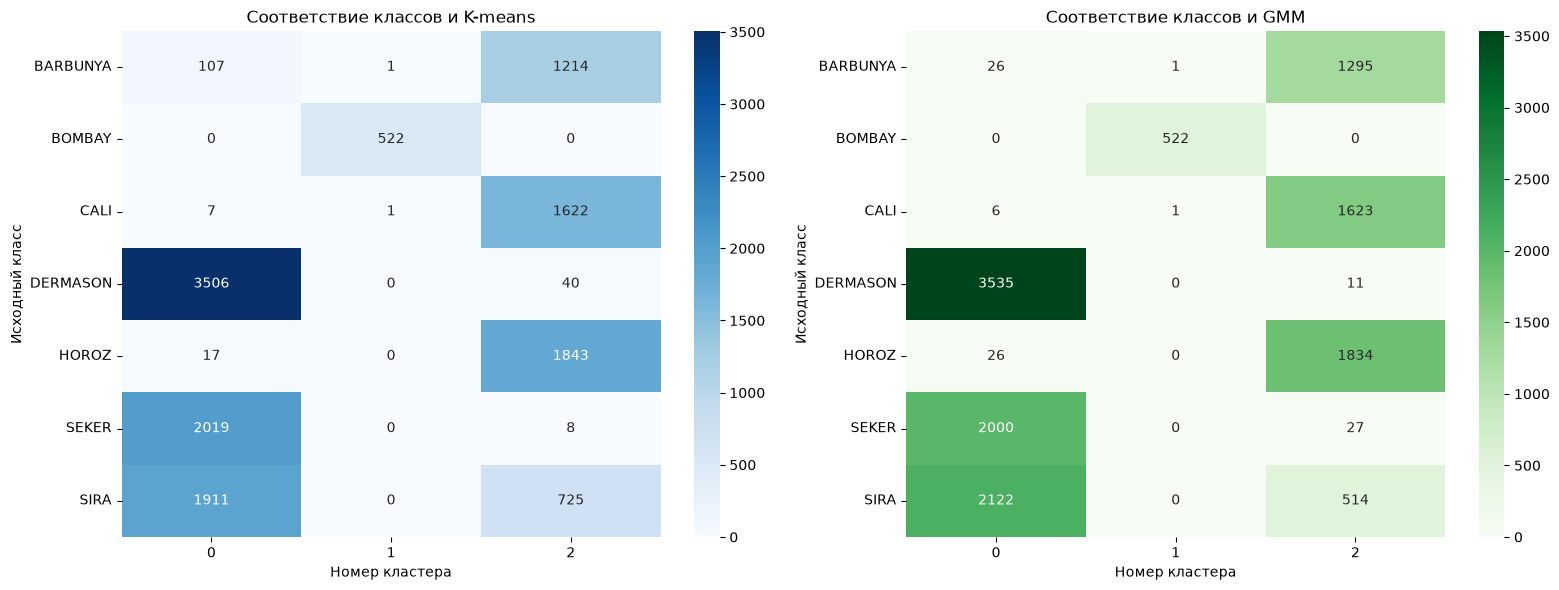

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

kmeans_cross = pd.crosstab(y_true, kmeans_labels)
gmm_cross = pd.crosstab(y_true, gmm_labels)

sns.heatmap(kmeans_cross, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Соответствие классов и K-means")
axes[0].set_xlabel("Номер кластера")
axes[0].set_ylabel("Исходный класс")

sns.heatmap(gmm_cross, annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Соответствие классов и GMM")
axes[1].set_xlabel("Номер кластера")
axes[1].set_ylabel("Исходный класс")

plt.tight_layout()
plt.show()

Тепловые карты позволяют подробнее рассмотреть, какие исходные классы попали в каждый кластер.

Для обоих алгоритмов кластер 1 полностью соответствует классу BOMBAY: все 522 объекта этого класса попали в одну группу.

Кластер 0 преимущественно включает классы DERMASON, SEKER и SIRA. Кластер 2 в основном состоит из классов BARBUNYA, CALI и HOROZ.

Результаты K-means и GMM близки, однако распределение отдельных объектов между кластерами немного различается. Например, GMM отнёс больше объектов класса SIRA к кластеру 0, а K-means - к кластеру 2.

Таким образом, оба алгоритма выявили схожую структуру данных, но не смогли полностью разделить все семь исходных классов на отдельные группы.

## Aнализ центров, расстояний и компактности кластеров.

In [ ]:
kmeans_centers = pd.DataFrame(
    kmeans_model.cluster_centers_,
    columns=X_scaled.columns
)

gmm_centers = pd.DataFrame(
    gmm_model.means_,
    columns=X_scaled.columns
)

print("Центры кластеров K-means:")
display(kmeans_centers.round(3))

print("Центры компонент GMM:")
display(gmm_centers.round(3))

Центры кластеров K-means:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,-0.532,-0.655,-0.699,-0.439,-0.608,-0.556,-0.534,-0.603,0.191,0.371,0.678,0.608,0.462,0.741,0.602,0.463
1,4.090,3.398,3.179,3.813,0.017,0.219,4.082,3.635,0.545,-0.057,-0.158,-0.125,-2.759,-1.468,-0.152,-0.745
2,0.345,0.582,0.664,0.243,0.841,0.750,0.349,0.488,-0.318,-0.509,-0.925,-0.832,-0.376,-0.887,-0.821,-0.570


Центры компонент GMM:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,-0.536,-0.657,-0.693,-0.454,-0.577,-0.520,-0.538,-0.607,0.165,0.359,0.665,0.574,0.479,0.719,0.567,0.439
1,4.090,3.398,3.179,3.813,0.017,0.219,4.082,3.635,0.545,-0.057,-0.158,-0.125,-2.759,-1.468,-0.152,-0.745
2,0.373,0.616,0.690,0.281,0.834,0.732,0.376,0.521,-0.293,-0.514,-0.947,-0.819,-0.422,-0.896,-0.807,-0.563


Анализ центров кластеров показал, что результаты K-means и GMM очень близки: значения средних по большинству признаков практически совпадают.

- **Кластер 0** характеризуется отрицательными значениями признаков размера фасоли (Area, Perimeter, MajorAxisLength, MinorAxisLength) и положительными значениями roundness, Compactness, ShapeFactor2 и ShapeFactor3. Это указывает на относительно небольшие и более компактные объекты.
- **Кластер 1** заметно отличается высокими положительными значениями признаков размера и отрицательными значениями ShapeFactor1, ShapeFactor2 и ShapeFactor4. Он объединяет объекты с наиболее крупными геометрическими размерами.
- **Кластер 2** имеет положительные значения признаков размера, но также высокие значения AspectRation и Eccentricity, а показатели roundness и Compactness отрицательны. Это указывает на более вытянутую форму объектов.

Таким образом, оба алгоритма выделили три схожие группы. Наиболее заметные различия между кластерами связаны с размерами и геометрической формой фасолин.

In [106]:
kmeans_distances = pd.DataFrame(
    cdist(kmeans_centers, kmeans_centers),
    index=["Кластер 0", "Кластер 1", "Кластер 2"],
    columns=["Кластер 0", "Кластер 1", "Кластер 2"]
)

gmm_distances = pd.DataFrame(
    cdist(gmm_centers, gmm_centers),
    index=["Компонента 0", "Компонента 1", "Компонента 2"],
    columns=["Компонента 0", "Компонента 1", "Компонента 2"]
)

print("Расстояния между центрами K-means:")
print(kmeans_distances.round(3))

print("Расстояния между центрами GMM:")
print(gmm_distances.round(3))

Расстояния между центрами K-means:
           Кластер 0  Кластер 1  Кластер 2
Кластер 0      0.000     11.402      4.746
Кластер 1     11.402      0.000      8.623
Кластер 2      4.746      8.623      0.000
Расстояния между центрами GMM:
              Компонента 0  Компонента 1  Компонента 2
Компонента 0         0.000        11.399         4.732
Компонента 1        11.399         0.000         8.535
Компонента 2         4.732         8.535         0.000


Расстояния между центрами кластеров K-means и GMM практически совпадают, что подтверждает сходство результатов двух алгоритмов.

Наибольшее расстояние наблюдается между кластерами 0 и 1 (11,402 у K-means и 11,399 у GMM). Это означает, что данные группы наиболее сильно различаются по совокупности признаков.

Наименьшее расстояние - между кластерами 0 и 2 (4,746 у K-means и 4,732 у GMM). Следовательно, эти группы расположены ближе друг к другу и имеют более похожие характеристики.

Таким образом, кластер 1 наиболее удалён от остальных групп, а кластеры 0 и 2 имеют более близкие центры.

In [107]:
def calculate_cluster_compactness(X_data, labels, centers, algorithm):
    distances = cdist(X_data, centers)
    results = []

    for cluster in range(len(centers)):
        cluster_distances = distances[labels == cluster, cluster]

        results.append({
            "Алгоритм": algorithm,
            "Кластер": cluster,
            "Количество объектов": len(cluster_distances),
            "Среднее расстояние до центра": cluster_distances.mean()
        })

    return pd.DataFrame(results)

kmeans_compactness = calculate_cluster_compactness(
    X_scaled.values, kmeans_labels, kmeans_centers.values, "K-means"
)

gmm_compactness = calculate_cluster_compactness(
    X_scaled.values, gmm_labels, gmm_centers.values, "GMM"
)

compactness_df = pd.concat(
    [kmeans_compactness, gmm_compactness],
    ignore_index=True
)

print(compactness_df.round(3))

  Алгоритм  Кластер  Количество объектов  Среднее расстояние до центра
0  K-means        0                 7567                         2.116
1  K-means        1                  524                         2.348
2  K-means        2                 5452                         2.866
3      GMM        0                 7715                         2.125
4      GMM        1                  524                         2.348
5      GMM        2                 5304                         2.887


Среднее расстояние объектов до центра позволяет оценить разброс данных внутри каждого кластера. Чем меньше это значение, тем компактнее кластер.

Для K-means наименьшее среднее расстояние получено для кластера 0 (2,116), а наибольшее - для кластера 2 (2,866).

Для GMM наблюдается аналогичная картина: кластер 0 имеет среднее расстояние 2,125, а кластер 2 - 2,887.

Таким образом, оба алгоритма сформировали группы с близкой структурой. Кластер 0 является наиболее компактным, а кластер 2 характеризуется наибольшим разбросом объектов.

## Общий вывод

В ходе лабораторной работы была выполнена кластеризация набора данных Dry Bean Dataset с использованием алгоритмов K-means и Gaussian Mixture Model (GMM).

На этапе предварительной обработки были изучены распределения признаков, выявлены и удалены 68 полных дубликатов. Числовые признаки были стандартизированы с помощью StandardScaler.

Для обоих алгоритмов было выбрано три кластера. Выбор подтверждается результатами оценки качества: Silhouette Score составил 0,4044 для K-means и 0,4057 для GMM.

Сравнение метрик показало, что GMM немного лучше согласуется с исходными классами по показателям ARI и NMI. При этом K-means продемонстрировал несколько лучшие значения Calinski-Harabasz и Davies-Bouldin.

Анализ центров и расстояний между ними показал, что результаты двух алгоритмов очень близки. Визуализация с помощью PCA позволила представить данные в двумерном пространстве, сохранив 81,91% общей дисперсии.

Тепловые карты показали, что оба алгоритма выделяют группу BOMBAY отдельно, однако остальные кластеры объединяют несколько исходных классов.

Таким образом, оба алгоритма позволили выявить структуру данных и получить сопоставимые результаты. GMM показал небольшое преимущество по некоторым метрикам, однако однозначного превосходства одного алгоритма по всем показателям не наблюдается.

# Список источников

1.   Scikit-learn: Machine Learning in Python / Pedregosa F., Varoquaux G., Gramfort A., et al. - Journal of Machine Learning Research, 2011. - Vol. 12. - P. 2825-2830.

2. Dry Bean Dataset // UCI Machine Learning Repository. — URL: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset (дата обращения: 24.10.2026).

3.   Воронцов К.В. Алгоритмы кластеризации и их применение: учебно-методическое пособие. - М.: МГУ, 2018. (Теория K-means, EM-алгоритма и метрик качества).

# Приложение. Полный листинг программного кода

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from zipfile import ZipFile

from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

from scipy.spatial.distance import cdist


DATA_PATH = "Dry_Bean_Dataset.xlsx"
df = pd.read_excel(DATA_PATH)

print("Размер датасета:", df.shape)

print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество пропусков в каждом столбце:")
print(df.isnull().sum())

print("\nОбщее количество пропущенных значений:")
print(df.isnull().sum().sum())

print("\nКоличество полностью дублирующихся строк:")
print(df.duplicated().sum())

print("\nКоличество бесконечных значений:")
print(
    df.select_dtypes(include="number")
      .isin([float("inf"), float("-inf")])
      .sum()
      .sum()
)

print("\nОсновные статистические характеристики:")
print(df.describe().round(2))

X = df.drop(columns=["Class"])
y_true = df["Class"]

print("Количество объектов:", X.shape[0])
print("Количество признаков:", X.shape[1])

print("\nПризнаки, используемые для кластеризации:")
print(X.columns.tolist())

print("\nРеальные классы (сохраняются только для последующей оценки):")
print(y_true.value_counts())


n_cols = 4
n_rows = int(np.ceil(X.shape[1] / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 16)
)

axes = axes.flatten()

for i, column in enumerate(X.columns):
    axes[i].hist(
        X[column],
        bins=40,
        edgecolor="black",
        alpha=0.75
    )

    axes[i].set_title(column)
    axes[i].set_xlabel("Значение")
    axes[i].set_ylabel("Частота")
    axes[i].grid(alpha=0.2)

for i in range(len(X.columns), len(axes)):
    axes[i].axis("off")

plt.suptitle(
    "Распределение числовых признаков Dry Bean Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(
    2, 8,
    figsize=(18, 10)
)

axes = axes.flatten()

for i, column in enumerate(X.columns):
    sns.boxplot(
        y=X[column],
        ax=axes[i],
        width=0.4
    )

    axes[i].set_title(column)
    axes[i].set_ylabel("Значение")
    axes[i].set_xlabel("")

plt.suptitle(
    "Диаграммы размаха числовых признаков",
    fontsize=16
)

plt.tight_layout()
plt.show()


outlier_stats = []

for column in X.columns:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (X[column] < lower_bound) |
        (X[column] > upper_bound)
    )

    outlier_stats.append({
        "Признак": column,
        "Количество выбросов": outliers.sum(),
        "Доля выбросов, %": outliers.mean() * 100
    })

outlier_df = pd.DataFrame(outlier_stats)

print(
    outlier_df.sort_values(
        "Доля выбросов, %",
        ascending=False
    ).round(2)
)


feature_variance = X.var().sort_values(ascending=False)

print(
    feature_variance.to_frame(
        name="Дисперсия признака"
    ).round(3)
)


plt.figure(figsize=(15, 12))

correlation_matrix = X.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()


scaler_analysis = StandardScaler()

X_scaled_analysis = scaler_analysis.fit_transform(X)

pca_analysis = PCA()

X_pca_analysis = pca_analysis.fit_transform(
    X_scaled_analysis
)

pca_variance = pd.DataFrame({
    "Главная компонента": [
        f"PC{i+1}" for i in range(X.shape[1])
    ],
    "Объясненная дисперсия, %":
        pca_analysis.explained_variance_ratio_ * 100,
    "Накопленная дисперсия, %":
        np.cumsum(
            pca_analysis.explained_variance_ratio_
        ) * 100
})

print(pca_variance.round(2))


plt.figure(figsize=(10, 5))

plt.bar(
    pca_variance["Главная компонента"],
    pca_variance["Объясненная дисперсия, %"]
)

plt.plot(
    pca_variance["Главная компонента"],
    pca_variance["Накопленная дисперсия, %"],
    marker="o",
    color="red",
    label="Накопленная дисперсия"
)

plt.xlabel("Главные компоненты")
plt.ylabel("Объясненная дисперсия, %")
plt.title("Анализ главных компонент PCA")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


print("Полных дубликатов:", df.duplicated().sum())

duplicate_features = (
    df.groupby(list(X.columns))["Class"]
    .nunique()
)

print(
    "Одинаковые наборы признаков с разными классами:",
    (duplicate_features > 1).sum()
)

df = df.drop_duplicates().copy()

X = df.drop(columns=["Class"])
y_true = df["Class"]

print("Размер данных после удаления дубликатов:", df.shape)
print("Оставшиеся дубликаты:", df.duplicated().sum())


scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

print("Данные после стандартизации:")
display(X_scaled.head())

print("\nСредние значения признаков:")
print(X_scaled.mean().round(4))

print("\nСтандартные отклонения признаков:")
print(X_scaled.std().round(4))


pca_loadings_model = PCA(n_components=2)
pca_loadings_model.fit(X_scaled)

loadings = pd.DataFrame(
    pca_loadings_model.components_.T *
    np.sqrt(pca_loadings_model.explained_variance_),
    index=X_scaled.columns,
    columns=["PC1", "PC2"]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    loadings,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Нагрузки признаков PCA")
plt.tight_layout()
plt.show()


selected_features = [
    "Area",
    "MajorAxisLength",
    "MinorAxisLength",
    "AspectRation",
    "Compactness"
]

plot_data = X_scaled[selected_features].sample(
    n=1500,
    random_state=42
)

sns.pairplot(
    plot_data,
    diag_kind="hist",
    plot_kws={"alpha": 0.3, "s": 12}
)

plt.suptitle(
    "Матрица диаграмм рассеивания признаков",
    y=1.02
)

plt.show()


inertia = []
silhouette_scores = []

k_range = range(2, 13)

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

    
results = pd.DataFrame({
    "Количество кластеров (k)": list(k_range),
    "Inertia": inertia,
    "Silhouette Score": silhouette_scores
})

print(results.round(4))


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(k_range, inertia, marker="o")
axes[0].set_title("Метод локтя (Elbow Method)")
axes[0].set_xlabel("Количество кластеров (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_range))
axes[0].grid(alpha=0.3)

axes[1].plot(k_range, silhouette_scores, marker="o", color="green")
axes[1].set_title("Силуэтный анализ (Silhouette Score)")
axes[1].set_xlabel("Количество кластеров (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_range))
axes[1].grid(alpha=0.3)

plt.suptitle("Определение оптимального количества кластеров для K-means")
plt.tight_layout()
plt.show()


kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

print("Кластеризация K-means завершена!")
print("\nКоличество объектов в каждом кластере:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

print("\nИтоговое значение Inertia:")
print(round(kmeans_model.inertia_, 4))


kmeans_metrics = {
    "Silhouette Score": silhouette_score(X_scaled, kmeans_labels),
    "Calinski-Harabasz Index": calinski_harabasz_score(X_scaled, kmeans_labels),
    "Davies-Bouldin Index": davies_bouldin_score(X_scaled, kmeans_labels),
    "Adjusted Rand Index": adjusted_rand_score(y_true, kmeans_labels),
    "Normalized Mutual Information": normalized_mutual_info_score(y_true, kmeans_labels)
}

kmeans_metrics_df = pd.DataFrame(
    list(kmeans_metrics.items()),
    columns=["Метрика", "Значение"]
)

print(kmeans_metrics_df.round(4))


aic_scores = []
bic_scores = []
gmm_silhouette_scores = []

k_range_gmm = range(2, 13)

for k in k_range_gmm:
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=3,
        reg_covar=1e-5
    )

    gmm.fit(X_scaled)

    labels = gmm.predict(X_scaled)

    aic_scores.append(gmm.aic(X_scaled))
    bic_scores.append(gmm.bic(X_scaled))

    gmm_silhouette_scores.append(
        silhouette_score(
            X_scaled,
            labels,
            sample_size=3000,
            random_state=42
        )
    )


gmm_results = pd.DataFrame({
    "Количество компонент (k)": list(k_range_gmm),
    "AIC": aic_scores,
    "BIC": bic_scores,
    "Silhouette Score": gmm_silhouette_scores
})

print(gmm_results.round(4))


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(k_range_gmm, aic_scores, marker="o")
axes[0].set_title("Критерий AIC")
axes[0].set_xlabel("Количество компонент (k)")
axes[0].set_ylabel("AIC")
axes[0].set_xticks(list(k_range_gmm))
axes[0].grid(alpha=0.3)

axes[1].plot(k_range_gmm, bic_scores, marker="o", color="orange")
axes[1].set_title("Критерий BIC")
axes[1].set_xlabel("Количество компонент (k)")
axes[1].set_ylabel("BIC")
axes[1].set_xticks(list(k_range_gmm))
axes[1].grid(alpha=0.3)

axes[2].plot(
    k_range_gmm,
    gmm_silhouette_scores,
    marker="o",
    color="green"
)
axes[2].set_title("Силуэтный анализ")
axes[2].set_xlabel("Количество компонент (k)")
axes[2].set_ylabel("Silhouette Score")
axes[2].set_xticks(list(k_range_gmm))
axes[2].grid(alpha=0.3)

plt.suptitle("Подбор количества компонент для Gaussian Mixture Model")
plt.tight_layout()
plt.show()


gmm_model = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42,
    n_init=3,
    reg_covar=1e-5
)

gmm_model.fit(X_scaled)

gmm_labels = gmm_model.predict(X_scaled)

df_gmm = df.copy()
df_gmm["GMM_Cluster"] = gmm_labels

print("Количество объектов в каждом кластере:")

print(
    df_gmm["GMM_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame(name="Количество объектов")
)


gmm_metrics = {
    "Silhouette Score": silhouette_score(X_scaled, gmm_labels),
    "Calinski-Harabasz Index": calinski_harabasz_score(X_scaled, gmm_labels),
    "Davies-Bouldin Index": davies_bouldin_score(X_scaled, gmm_labels),
    "Adjusted Rand Index": adjusted_rand_score(y_true, gmm_labels),
    "Normalized Mutual Information": normalized_mutual_info_score(y_true, gmm_labels)
}

gmm_metrics_df = pd.DataFrame(
    list(gmm_metrics.items()),
    columns=["Метрика", "Значение"]
)

print(gmm_metrics_df.round(4))


comparison_df = pd.DataFrame({
    "Метрика": list(kmeans_metrics.keys()),
    "K-means": list(kmeans_metrics.values()),
    "GMM": list(gmm_metrics.values())
})

print(comparison_df.round(4))


kmeans_parameter_results = []

for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    kmeans_parameter_results.append({
        "Количество кластеров": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels)
    })

kmeans_parameter_df = pd.DataFrame(kmeans_parameter_results)
display(kmeans_parameter_df.round(4))


fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics = [
    ("Inertia", "Inertia"),
    ("Silhouette Score", "Silhouette Score"),
    ("Calinski-Harabasz", "Calinski-Harabasz Index"),
    ("Davies-Bouldin", "Davies-Bouldin Index")
]

for ax, (column, title) in zip(axes.flat, metrics):
    ax.plot(
        kmeans_parameter_df["Количество кластеров"],
        kmeans_parameter_df[column],
        marker="o"
    )
    ax.set_title(title)
    ax.set_xlabel("Количество кластеров")
    ax.set_ylabel(column)
    ax.set_xticks(kmeans_parameter_df["Количество кластеров"])
    ax.grid(True)

plt.tight_layout()
plt.show()


pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

print("Объяснённая дисперсия:")
print(pca_2d.explained_variance_ratio_)
print("Суммарная доля:", pca_2d.explained_variance_ratio_.sum())


fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Исходные классы
true_labels, y_encoded = np.unique(y_true, return_inverse=True)

scatter = axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=y_encoded, cmap="tab10", s=8, alpha=0.6
)
axes[0].set_title("Исходные классы фасоли")

# K-means
axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=kmeans_labels, cmap="viridis", s=8, alpha=0.6
)
axes[1].set_title("Кластеризация K-means")

# GMM
axes[2].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=gmm_labels, cmap="viridis", s=8, alpha=0.6
)
axes[2].set_title("Кластеризация GMM")

for ax in axes:
    ax.set_xlabel("Первая главная компонента (PC1)")
    ax.set_ylabel("Вторая главная компонента (PC2)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

kmeans_cross = pd.crosstab(y_true, kmeans_labels)
gmm_cross = pd.crosstab(y_true, gmm_labels)

sns.heatmap(kmeans_cross, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Соответствие классов и K-means")
axes[0].set_xlabel("Номер кластера")
axes[0].set_ylabel("Исходный класс")

sns.heatmap(gmm_cross, annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Соответствие классов и GMM")
axes[1].set_xlabel("Номер кластера")
axes[1].set_ylabel("Исходный класс")

plt.tight_layout()
plt.show()


kmeans_centers = pd.DataFrame(
    kmeans_model.cluster_centers_,
    columns=X_scaled.columns
)

gmm_centers = pd.DataFrame(
    gmm_model.means_,
    columns=X_scaled.columns
)

print("Центры кластеров K-means:")
display(kmeans_centers.round(3))

print("Центры компонент GMM:")
display(gmm_centers.round(3))


kmeans_distances = pd.DataFrame(
    cdist(kmeans_centers, kmeans_centers),
    index=["Кластер 0", "Кластер 1", "Кластер 2"],
    columns=["Кластер 0", "Кластер 1", "Кластер 2"]
)

gmm_distances = pd.DataFrame(
    cdist(gmm_centers, gmm_centers),
    index=["Компонента 0", "Компонента 1", "Компонента 2"],
    columns=["Компонента 0", "Компонента 1", "Компонента 2"]
)

print("Расстояния между центрами K-means:")
print(kmeans_distances.round(3))

print("Расстояния между центрами GMM:")
print(gmm_distances.round(3))


def calculate_cluster_compactness(X_data, labels, centers, algorithm):
    distances = cdist(X_data, centers)
    results = []

    for cluster in range(len(centers)):
        cluster_distances = distances[labels == cluster, cluster]

        results.append({
            "Алгоритм": algorithm,
            "Кластер": cluster,
            "Количество объектов": len(cluster_distances),
            "Среднее расстояние до центра": cluster_distances.mean()
        })

    return pd.DataFrame(results)

kmeans_compactness = calculate_cluster_compactness(
    X_scaled.values, kmeans_labels, kmeans_centers.values, "K-means"
)

gmm_compactness = calculate_cluster_compactness(
    X_scaled.values, gmm_labels, gmm_centers.values, "GMM"
)

compactness_df = pd.concat(
    [kmeans_compactness, gmm_compactness],
    ignore_index=True
)

print(compactness_df.round(3))
